In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [3]:
dataset_path = "../dataset"

print("Files in dataset folder:")

for file in os.listdir(dataset_path):
    print(file)

Files in dataset folder:
combined_gee_pm25.csv
gee_features_daily.csv
pm25.csv


In [4]:
pm25 = pd.read_csv("../dataset/pm25.csv")

gee = pd.read_csv("../dataset/gee_features_daily.csv")

combined = pd.read_csv("../dataset/combined_gee_pm25.csv")

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [5]:
print("PM2.5 dataset:", pm25.shape)

print("GEE features dataset:", gee.shape)

print("Combined dataset:", combined.shape)

PM2.5 dataset: (88041, 5)
GEE features dataset: (164208, 13)
Combined dataset: (41718, 15)


In [6]:
display(combined.head())

,date,datetime_utc,id,latitude,longitude,temperature_celsius,pressure_mb,wind_u,wind_v,NO2,CO,O3,AOD,pm25,sensor_name
0,2016-11-25,2016-11-25 00:00:00,1,38.788056,-0.697222,6.493180,946.288660,0.230240,0.735303,NaN,NaN,NaN,0.1110,2.750000,ONTINYENT
1,2016-11-25,2016-11-25 00:00:00,36,39.945278,-0.056389,9.251236,993.626994,0.783218,-0.592618,NaN,NaN,NaN,0.0220,11.666667,ALMASSORA-C. P. OCHANDO
2,2016-11-30,2016-11-30 00:00:00,35,40.051944,-0.189722,10.044782,981.911432,-2.211047,-1.568971,NaN,NaN,NaN,0.2380,2.400000,ALCORA
3,2016-11-30,2016-11-30 00:00:00,37,40.062222,0.072778,12.299584,1008.794766,-3.236886,-2.804465,NaN,NaN,NaN,0.2480,2.600000,BENICASSIM
4,2016-12-02,2016-12-02 00:00:00,1,38.788056,-0.697222,9.350630,953.114180,0.953454,0.293060,NaN,NaN,NaN,0.0755,2.750000,ONTINYENT


In [7]:
combined.info()

<class 'pandas.DataFrame'>
RangeIndex: 41718 entries, 0 to 41717
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   date                 41718 non-null  str    
 1   datetime_utc         41718 non-null  str    
 2   id                   41718 non-null  int64  
 3   latitude             41718 non-null  float64
 4   longitude            41718 non-null  float64
 5   temperature_celsius  41718 non-null  float64
 6   pressure_mb          41718 non-null  float64
 7   wind_u               41718 non-null  float64
 8   wind_v               41718 non-null  float64
 9   NO2                  39308 non-null  float64
 10  CO                   39308 non-null  float64
 11  O3                   39267 non-null  float64
 12  AOD                  41718 non-null  float64
 13  pm25                 41718 non-null  float64
 14  sensor_name          41718 non-null  str    
dtypes: float64(11), int64(1), str(3)
memory usage: 

In [8]:
missing_values = combined.isnull().sum()

missing_percentage = (combined.isnull().sum() / len(combined)) * 100

missing_report = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage (%)": missing_percentage
})

display(missing_report.sort_values(
    by="Missing Percentage (%)",
    ascending=False
))

,Missing Values,Missing Percentage (%)
O3,2451,5.875162
CO,2410,5.776883
NO2,2410,5.776883
latitude,0,0.000000
date,0,0.000000
datetime_utc,0,0.000000
id,0,0.000000
pressure_mb,0,0.000000
temperature_celsius,0,0.000000
longitude,0,0.000000


In [9]:
print("Number of duplicate rows:",
      combined.duplicated().sum())

Number of duplicate rows: 0


In [10]:
combined["date"] = pd.to_datetime(combined["date"])

print("First date:", combined["date"].min())
print("Last date:", combined["date"].max())

print("Number of unique dates:",
      combined["date"].nunique())

print("Number of stations:",
      combined["sensor_name"].nunique())

First date: 2016-11-25 00:00:00
Last date: 2026-04-06 00:00:00
Number of unique dates: 2305
Number of stations: 94


In [14]:
# Check duplicated station-date combinations

station_date_duplicates = combined.duplicated(
    subset=["id", "date"]
).sum()

print("Duplicated station-date combinations:",
      station_date_duplicates)

Duplicated station-date combinations: 0


In [15]:
# Descriptive statistics of PM2.5

print(combined["pm25"].describe())

count    41718.000000
mean         9.099293
std         23.141811
min       -999.000000
25%          4.500000
50%          7.750000
75%         12.000000
max       1000.000000
Name: pm25, dtype: float64


In [18]:
print("Negative values:",
      (combined["pm25"] < 0).sum())

print("Zero values:",
      (combined["pm25"] == 0).sum())

print("Values >= 500:",
      (combined["pm25"] >= 500).sum())

print("Minimum PM2.5:",
      combined["pm25"].min())

print("Maximum PM2.5:",
      combined["pm25"].max())

Negative values: 273
Zero values: 454
Values >= 500: 8
Minimum PM2.5: -999.0
Maximum PM2.5: 1000.0


In [19]:
# Count special and invalid PM2.5 values

print("Number of -999 values:",
      (combined["pm25"] == -999).sum())

print("Negative values excluding -999:",
      ((combined["pm25"] < 0) &
       (combined["pm25"] != -999)).sum())

print("Zero values:",
      (combined["pm25"] == 0).sum())

print("Values between 500 and 1000:",
      ((combined["pm25"] >= 500) &
       (combined["pm25"] <= 1000)).sum())

Number of -999 values: 4
Negative values excluding -999: 269
Zero values: 454
Values between 500 and 1000: 8


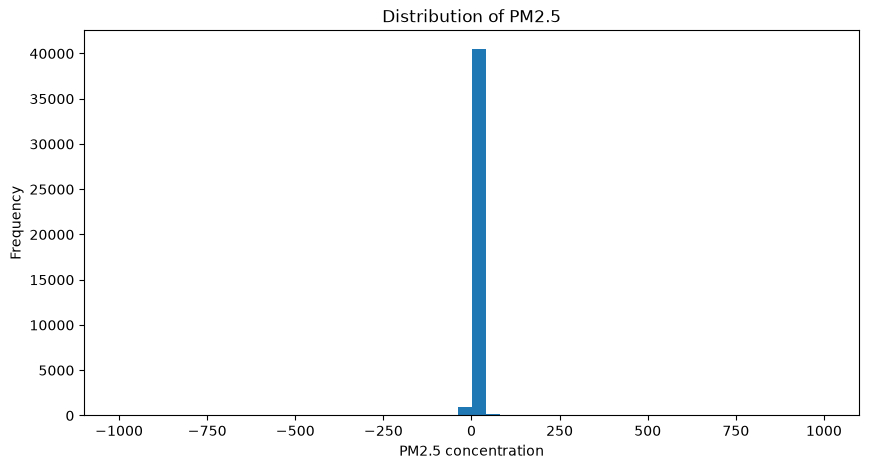

In [20]:
plt.figure(figsize=(10, 5))

plt.hist(combined["pm25"], bins=50)

plt.title("Distribution of PM2.5")
plt.xlabel("PM2.5 concentration")
plt.ylabel("Frequency")

plt.show()

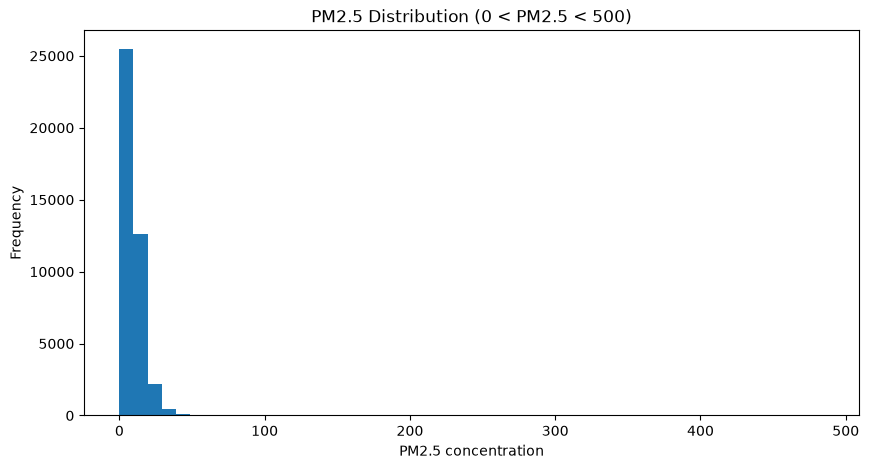

In [21]:
# Temporary filtering for visualization only

pm25_visual = combined.loc[
    (combined["pm25"] > 0) &
    (combined["pm25"] < 500),
    "pm25"
]

plt.figure(figsize=(10, 5))

plt.hist(pm25_visual, bins=50)

plt.title("PM2.5 Distribution (0 < PM2.5 < 500)")
plt.xlabel("PM2.5 concentration")
plt.ylabel("Frequency")

plt.show()

In [22]:
negative_values = combined.loc[
    combined["pm25"] < 0, "pm25"
].value_counts().sort_index()

print("Negative PM2.5 values:")
print(negative_values)

Negative PM2.5 values:
pm25
-999.000000    4
-927.500000    1
-927.000000    2
-926.928571    1
-926.785714    2
              ..
-0.084615      1
-0.066667      1
-0.055556      1
-0.038462      1
-0.013636      1
Name: count, Length: 66, dtype: int64


In [23]:
# Display the 15 highest PM2.5 observations

highest_values = combined.nlargest(
    15, "pm25"
)

display(
    highest_values[
        ["date", "id", "sensor_name", "pm25"]
    ]
)

,date,id,sensor_name,pm25
12740,2022-01-06,28,HOSTELERÍA,1000.0000
28349,2024-08-08,90,CENCA1,1000.0000
12145,2021-12-04,29,E4:RINCONCILLO,998.0000
12170,2021-12-05,29,E4:RINCONCILLO,998.0000
12195,2021-12-06,29,E4:RINCONCILLO,998.0000
12211,2021-12-07,29,E4:RINCONCILLO,626.3750
29569,2024-09-17,90,CENCA1,508.1807
28462,2024-08-11,90,CENCA1,500.0000
29186,2024-09-04,90,CENCA1,484.9815
11856,2021-11-22,18,LOS BARRIOS,483.8750


In [24]:
# Identify all PM2.5 values >= 500

extreme_pm25 = combined[
    combined["pm25"] >= 500
][["date", "id", "sensor_name", "pm25"]]

print("Number of extreme observations:",
      len(extreme_pm25))

display(extreme_pm25.sort_values("pm25", ascending=False))

Number of extreme observations: 8


,date,id,sensor_name,pm25
28349,2024-08-08,90,CENCA1,1000.0000
12740,2022-01-06,28,HOSTELERÍA,1000.0000
12145,2021-12-04,29,E4:RINCONCILLO,998.0000
12170,2021-12-05,29,E4:RINCONCILLO,998.0000
12195,2021-12-06,29,E4:RINCONCILLO,998.0000
12211,2021-12-07,29,E4:RINCONCILLO,626.3750
29569,2024-09-17,90,CENCA1,508.1807
28462,2024-08-11,90,CENCA1,500.0000


In [25]:
# Examine observations where PM2.5 equals zero

zero_pm25 = combined[
    combined["pm25"] == 0
][["date", "id", "sensor_name", "pm25"]]

print("Number of zero observations:", len(zero_pm25))

display(zero_pm25.head(15))

Number of zero observations: 454


,date,id,sensor_name,pm25
364,2017-03-19,72,FR03030,0.0
634,2017-05-10,35,ALCORA,0.0
1495,2017-07-20,35,ALCORA,0.0
3833,2019-07-05,1,ONTINYENT,0.0
3834,2019-07-05,6,VALÈNCIA-PISTA DE SILLA,0.0
3842,2019-07-05,38,BURRIANA,0.0
3843,2019-07-05,36,ALMASSORA-C. P. OCHANDO,0.0
3844,2019-07-05,35,ALCORA,0.0
3845,2019-07-05,37,BENICASSIM,0.0
3856,2019-07-06,38,BURRIANA,0.0


In [26]:
# Count invalid PM2.5 observations per station

invalid_pm25 = combined[
    (combined["pm25"] <= 0) |
    (combined["pm25"] >= 500)
]

invalid_by_station = (
    invalid_pm25.groupby("sensor_name")
    .size()
    .sort_values(ascending=False)
)

print("Invalid observations per station:")
display(invalid_by_station.head(15))

Invalid observations per station:


sensor_name
VILAMARXANT                89
ONTINYENT                  80
SAN ROQUE (S6)             60
TORRENT-EL VEDAT           47
BENICASSIM                 38
ALMASSORA-C. P. OCHANDO    36
BURRIANA                   32
ALCORA                     31
ELDA-LACY                  28
Rognac les Brets           26
E2: ALCORNOCALES           25
QUART DE POBLET            21
E4:RINCONCILLO             20
ALBALAT DELS TARONGERS     20
SAGUNT CEA                 20
dtype: int64

In [27]:
# Calculate total observations per station
total_by_station = combined.groupby("sensor_name").size()

# Calculate invalid observations per station
invalid_by_station = invalid_pm25.groupby("sensor_name").size()

# Calculate invalid percentage
invalid_rate = (
    invalid_by_station / total_by_station * 100
).fillna(0)

# Create a summary table
station_quality = pd.DataFrame({
    "Total observations": total_by_station,
    "Invalid observations": invalid_by_station,
    "Invalid percentage (%)": invalid_rate
})

# Sort by invalid percentage
station_quality = station_quality.sort_values(
    "Invalid percentage (%)",
    ascending=False
)

display(station_quality.head(15).round(2))

,Total observations,Invalid observations,Invalid percentage (%)
sensor_name,,,
064F,1,1.0,100.00
mimiz,4,4.0,100.00
testcompnex,4,4.0,100.00
TORRENT-EL VEDAT,136,47.0,34.56
VILAMARXANT,435,89.0,20.46
ONTINYENT,527,80.0,15.18
SAN ROQUE (S6),705,60.0,8.51
Rognac les Brets,425,26.0,6.12
BENICASSIM,808,38.0,4.70


In [28]:
# Create a cleaned copy of the dataset
combined_cleaned = combined[
    (combined["pm25"] > 0) &
    (combined["pm25"] < 500)
].copy()

# Compare dataset sizes
print("Original dataset:", combined.shape)
print("Cleaned dataset:", combined_cleaned.shape)

# Number of removed observations
print("Removed observations:",
      len(combined) - len(combined_cleaned))

Original dataset: (41718, 15)
Cleaned dataset: (40983, 15)
Removed observations: 735


In [30]:
# Descriptive statistics
print(combined_cleaned["pm25"].describe())

# Additional statistical measures
print("\nSkewness:", combined_cleaned["pm25"].skew())
print("Kurtosis:", combined_cleaned["pm25"].kurtosis())

count    40983.000000
mean         9.457765
std          9.729713
min          0.006667
25%          4.673864
50%          7.851176
75%         12.086667
max        484.981500
Name: pm25, dtype: float64

Skewness: 17.82910231943009
Kurtosis: 651.6721071025989


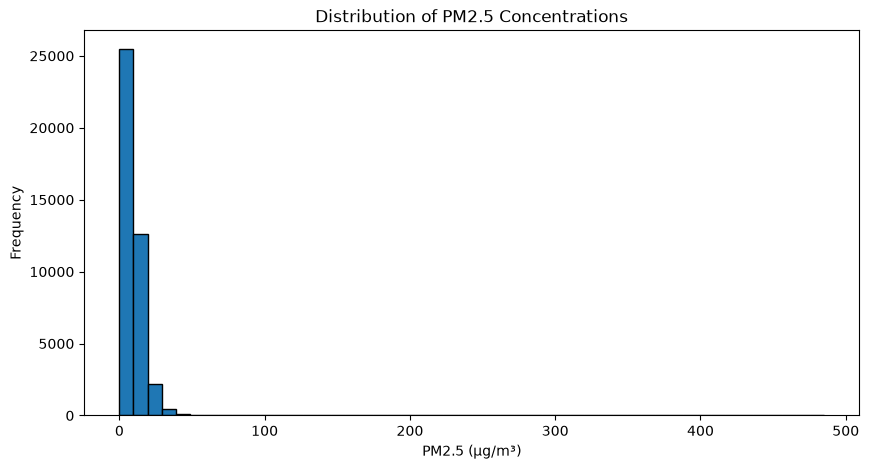

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    combined_cleaned["pm25"],
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of PM2.5 Concentrations")
plt.xlabel("PM2.5 (µg/m³)")
plt.ylabel("Frequency")

plt.show()

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_10516\846225153.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


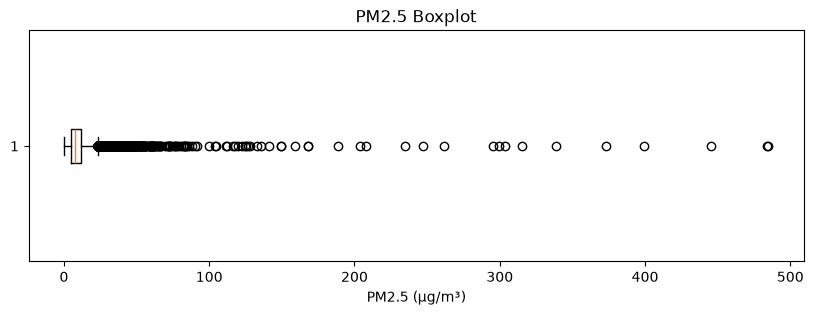

In [32]:
plt.figure(figsize=(10, 3))

plt.boxplot(
    combined_cleaned["pm25"],
    vert=False
)

plt.title("PM2.5 Boxplot")
plt.xlabel("PM2.5 (µg/m³)")

plt.show()

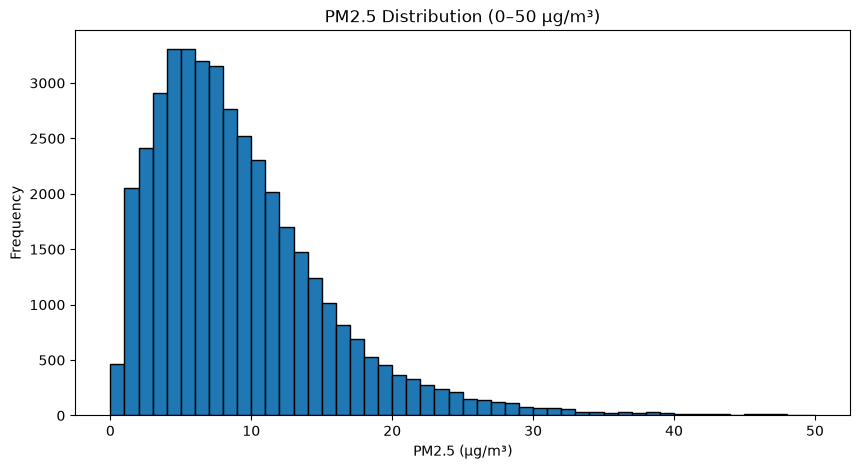

In [33]:
plt.figure(figsize=(10, 5))

plt.hist(
    combined_cleaned["pm25"],
    bins=50,
    range=(0, 50),
    edgecolor="black"
)

plt.title("PM2.5 Distribution (0–50 µg/m³)")
plt.xlabel("PM2.5 (µg/m³)")
plt.ylabel("Frequency")

plt.show()

In [34]:
# Check missing values in numerical variables

features = [
    "AOD",
    "NO2",
    "CO",
    "O3",
    "temperature_celsius",
    "pressure_mb",
    "wind_u",
    "wind_v"
]

missing_summary = pd.DataFrame({
    "Missing values": combined_cleaned[features].isnull().sum(),
    "Missing percentage (%)":
        combined_cleaned[features].isnull().mean() * 100
})

display(missing_summary.round(2))

,Missing values,Missing percentage (%)
AOD,0,0.00
NO2,2407,5.87
CO,2407,5.87
O3,2448,5.97
temperature_celsius,0,0.00
pressure_mb,0,0.00
wind_u,0,0.00
wind_v,0,0.00


In [35]:
# Descriptive statistics for all numerical features

display(combined_cleaned[features].describe().round(2))

,AOD,NO2,CO,O3,temperature_celsius,pressure_mb,wind_u,wind_v
count,40983.00,38576.0,38576.00,38535.00,40983.00,40983.00,40983.00,40983.00
mean,0.15,0.0,0.03,0.14,18.27,993.82,0.34,-0.18
std,0.11,0.0,0.00,0.01,6.39,17.18,2.53,1.39
min,0.00,0.0,0.01,0.10,-1.28,930.32,-11.10,-10.86
25%,0.08,0.0,0.03,0.13,12.97,987.99,-0.98,-0.73
50%,0.13,0.0,0.03,0.14,18.49,997.73,0.21,0.04
75%,0.19,0.0,0.03,0.15,23.79,1005.37,1.68,0.66
max,5.48,0.0,0.10,0.23,34.87,1033.66,9.66,8.49


In [36]:
# Skewness and kurtosis

distribution_stats = pd.DataFrame({
    "Skewness": combined_cleaned[features].skew(),
    "Kurtosis": combined_cleaned[features].kurtosis()
})

display(distribution_stats.round(2))

,Skewness,Kurtosis
AOD,7.61,246.85
NO2,2.12,9.18
CO,1.40,13.77
O3,1.15,2.28
temperature_celsius,-0.10,-0.97
pressure_mb,-1.09,0.71
wind_u,-0.18,1.03
wind_v,-1.28,4.39


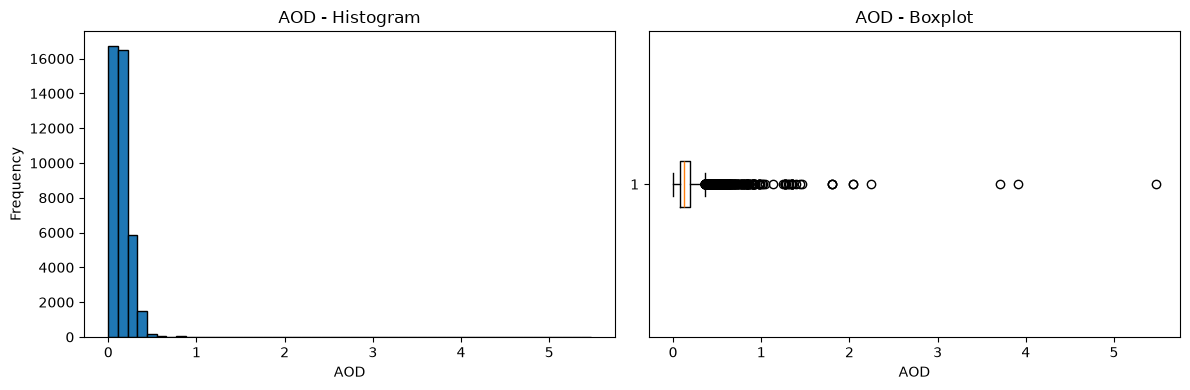

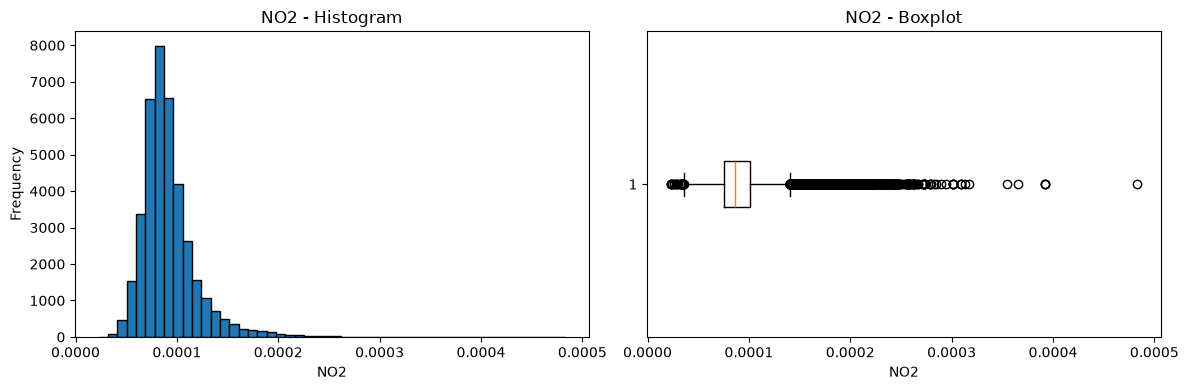

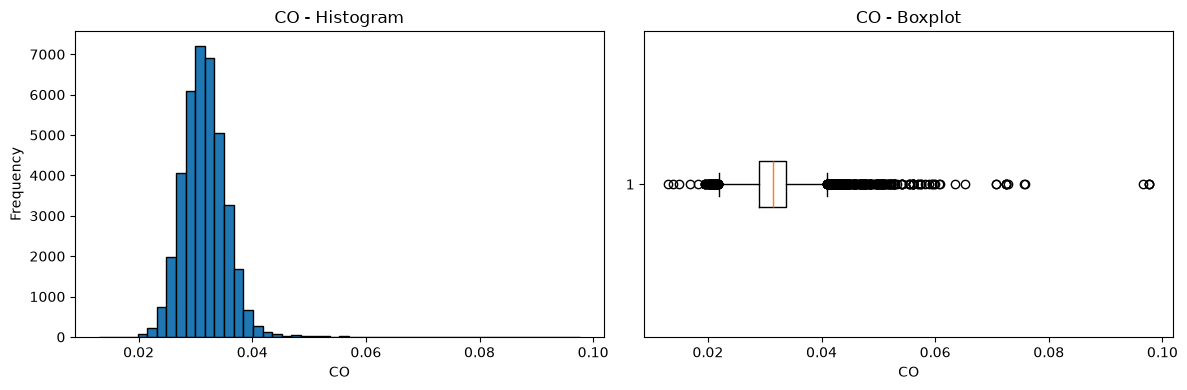

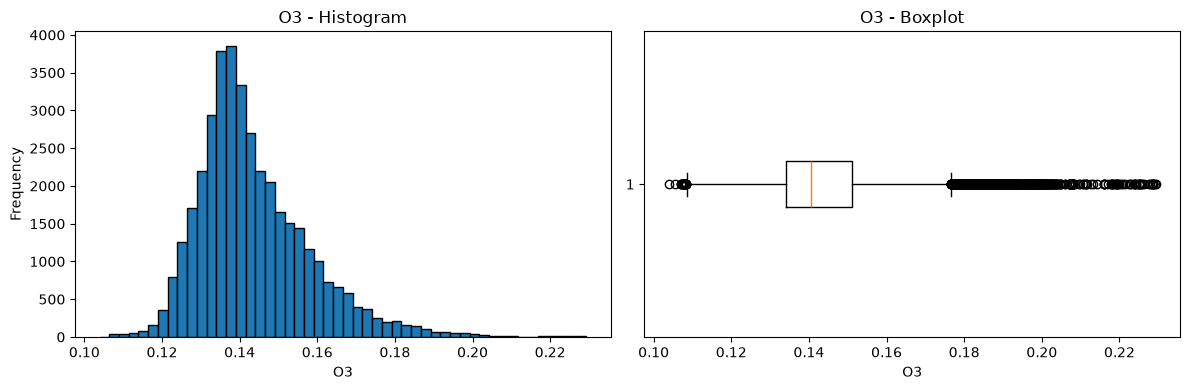

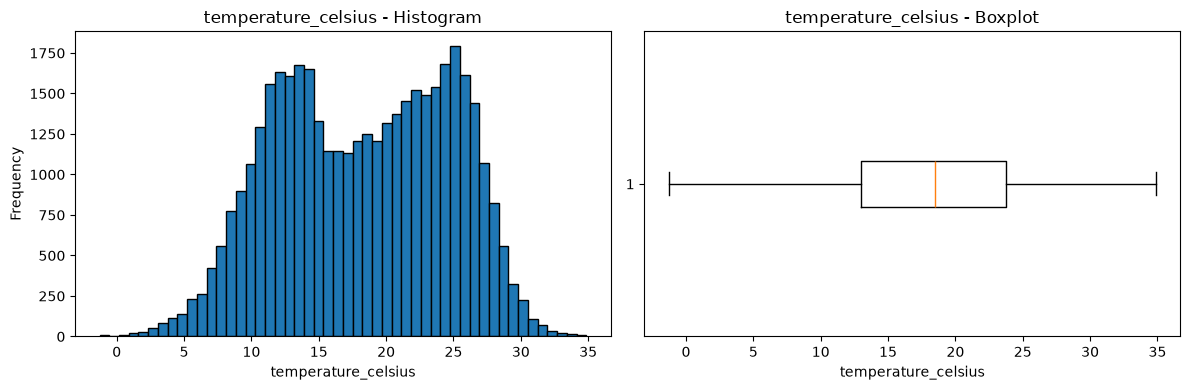

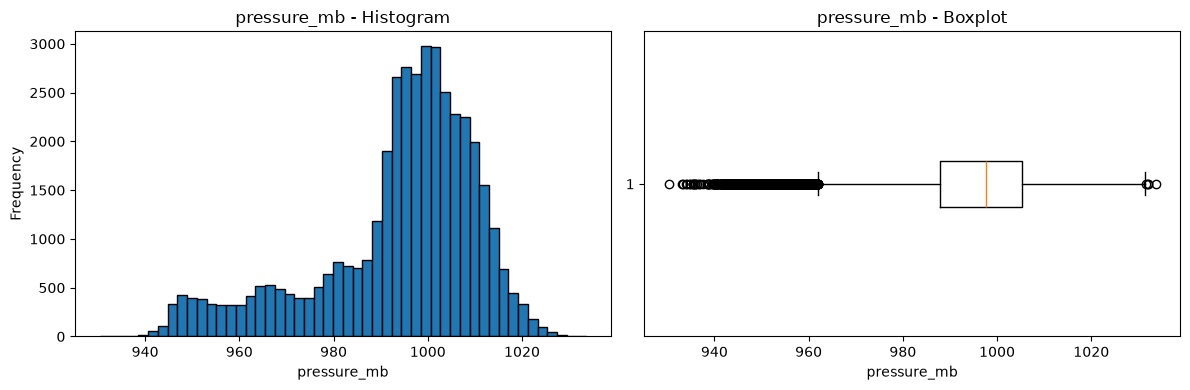

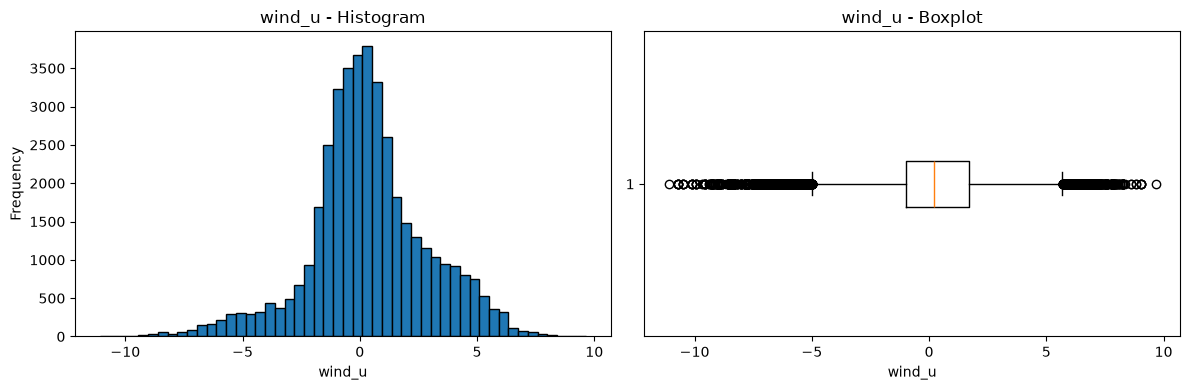

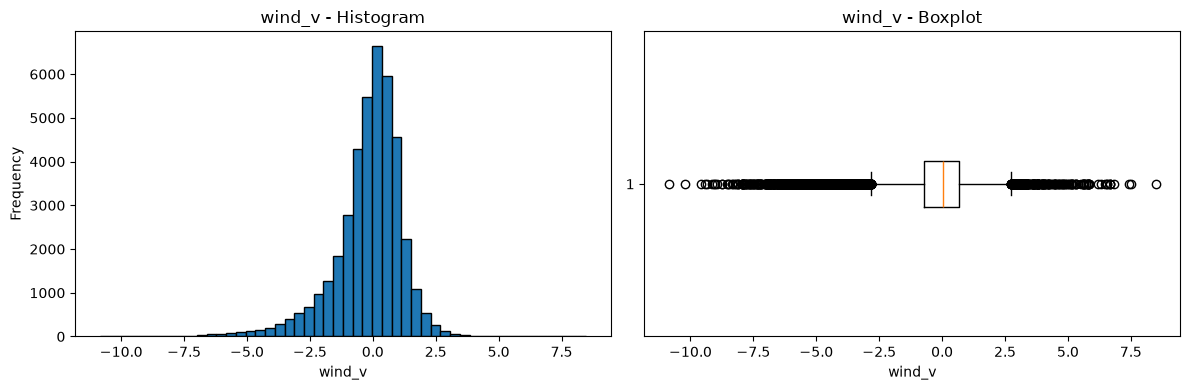

In [38]:
import matplotlib.pyplot as plt

for feature in features:

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Histogram
    axes[0].hist(
        combined_cleaned[feature].dropna(),
        bins=50,
        edgecolor="black"
    )
    axes[0].set_title(f"{feature} - Histogram")
    axes[0].set_xlabel(feature)
    axes[0].set_ylabel("Frequency")

    # Boxplot
    axes[1].boxplot(
        combined_cleaned[feature].dropna(),
        orientation="horizontal"
    )
    axes[1].set_title(f"{feature} - Boxplot")
    axes[1].set_xlabel(feature)

    plt.tight_layout()
    plt.show()

In [39]:
# Detect outliers using the IQR method

outlier_results = []

for feature in ["pm25"] + features:

    data = combined_cleaned[feature].dropna()

    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = data[(data < lower) | (data > upper)]

    outlier_results.append({
        "Variable": feature,
        "Lower limit": lower,
        "Upper limit": upper,
        "Outliers count": len(outliers),
        "Outliers percentage (%)": len(outliers) / len(data) * 100
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary.round(3))

,Variable,Lower limit,Upper limit,Outliers count,Outliers percentage (%)
0,pm25,-6.445,23.206,1613,3.936
1,AOD,-0.091,0.365,1114,2.718
2,NO2,0.000,0.000,2061,5.343
3,CO,0.022,0.041,572,1.483
4,O3,0.108,0.177,1219,3.163
5,temperature_celsius,-3.267,40.021,0,0.000
6,pressure_mb,961.916,1031.438,3179,7.757
7,wind_u,-4.988,5.688,2133,5.205
8,wind_v,-2.819,2.750,2234,5.451


In [40]:
import numpy as np
from scipy.stats import zscore

# Variables to analyze
all_features = ["pm25"] + features

zscore_results = []

for feature in all_features:

    # Ignore missing values
    data = combined_cleaned[feature].dropna()

    # Calculate Z-scores
    z_scores = zscore(data)

    # Detect outliers
    outliers = np.abs(z_scores) > 3

    # Store results
    zscore_results.append({
        "Variable": feature,
        "Outliers count": outliers.sum(),
        "Outliers percentage (%)": outliers.mean() * 100
    })

# Create summary table
zscore_summary = pd.DataFrame(zscore_results)

display(zscore_summary.round(3))

,Variable,Outliers count,Outliers percentage (%)
0,pm25,255,0.622
1,AOD,299,0.730
2,NO2,731,1.895
3,CO,257,0.666
4,O3,463,1.202
5,temperature_celsius,4,0.010
6,pressure_mb,72,0.176
7,wind_u,281,0.686
8,wind_v,753,1.837


In [41]:
from sklearn.ensemble import IsolationForest

isolation_results = []

for feature in ["pm25"] + features:

    data = combined_cleaned[feature].dropna().to_frame()

    model = IsolationForest(
        n_estimators=100,
        contamination="auto",
        random_state=42
    )

    predictions = model.fit_predict(data)

    # -1 means outlier, 1 means normal
    outliers_count = (predictions == -1).sum()

    isolation_results.append({
        "Variable": feature,
        "Outliers count": outliers_count,
        "Outliers percentage (%)":
            outliers_count / len(data) * 100
    })

isolation_summary = pd.DataFrame(isolation_results)

display(isolation_summary.round(3))

,Variable,Outliers count,Outliers percentage (%)
0,pm25,7815,19.069
1,AOD,8348,20.369
2,NO2,7695,19.948
3,CO,6394,16.575
4,O3,8937,23.192
5,temperature_celsius,8248,20.125
6,pressure_mb,12754,31.120
7,wind_u,10333,25.213
8,wind_v,6879,16.785


In [47]:
from sklearn.neighbors import LocalOutlierFactor

lof_results = []

for feature in ["pm25"] + features:

    data = combined_cleaned[feature].dropna().to_frame()

    lof = LocalOutlierFactor(
        n_neighbors=20,
        contamination="auto"
    )

    predictions = lof.fit_predict(data)

    outliers_count = (predictions == -1).sum()

    lof_results.append({
        "Variable": feature,
        "Outliers count": outliers_count,
        "Outliers percentage (%)":
            outliers_count / len(data) * 100
    })

lof_summary = pd.DataFrame(lof_results)

display(lof_summary.round(3))

c:\Users\Lenovo\Desktop\PM25_Forecasting\.venv\Lib\site-packages\sklearn\neighbors\_lof.py:327: UserWarning: Duplicate values are leading to incorrect results. Increase the number of neighbors for more accurate results.
  warnings.warn(


,Variable,Outliers count,Outliers percentage (%)
0,pm25,3500,8.540
1,AOD,4856,11.849
2,NO2,241,0.625
3,CO,324,0.840
4,O3,231,0.599
5,temperature_celsius,241,0.588
6,pressure_mb,285,0.695
7,wind_u,299,0.730
8,wind_v,249,0.608


In [48]:
# Select numerical variables
correlation_features = [
    "pm25",
    "AOD",
    "NO2",
    "CO",
    "O3",
    "temperature_celsius",
    "pressure_mb",
    "wind_u",
    "wind_v"
]

# Calculate Pearson correlation matrix
pearson_corr = combined_cleaned[correlation_features].corr(
    method="pearson"
)

# Display correlation matrix
display(pearson_corr.round(3))

,pm25,AOD,NO2,CO,O3,temperature_celsius,pressure_mb,wind_u,wind_v
pm25,1.000,0.094,0.159,0.041,-0.087,-0.006,0.113,-0.079,0.059
AOD,0.094,1.000,-0.062,0.133,-0.010,0.332,0.017,-0.247,0.164
NO2,0.159,-0.062,1.000,0.100,-0.094,-0.055,0.166,-0.089,0.106
CO,0.041,0.133,0.100,1.000,0.210,-0.126,0.198,0.033,-0.075
O3,-0.087,-0.010,-0.094,0.210,1.000,-0.320,-0.034,0.162,-0.120
temperature_celsius,-0.006,0.332,-0.055,-0.126,-0.320,1.000,-0.062,-0.179,0.338
pressure_mb,0.113,0.017,0.166,0.198,-0.034,-0.062,1.000,-0.086,-0.044
wind_u,-0.079,-0.247,-0.089,0.033,0.162,-0.179,-0.086,1.000,-0.218
wind_v,0.059,0.164,0.106,-0.075,-0.120,0.338,-0.044,-0.218,1.000


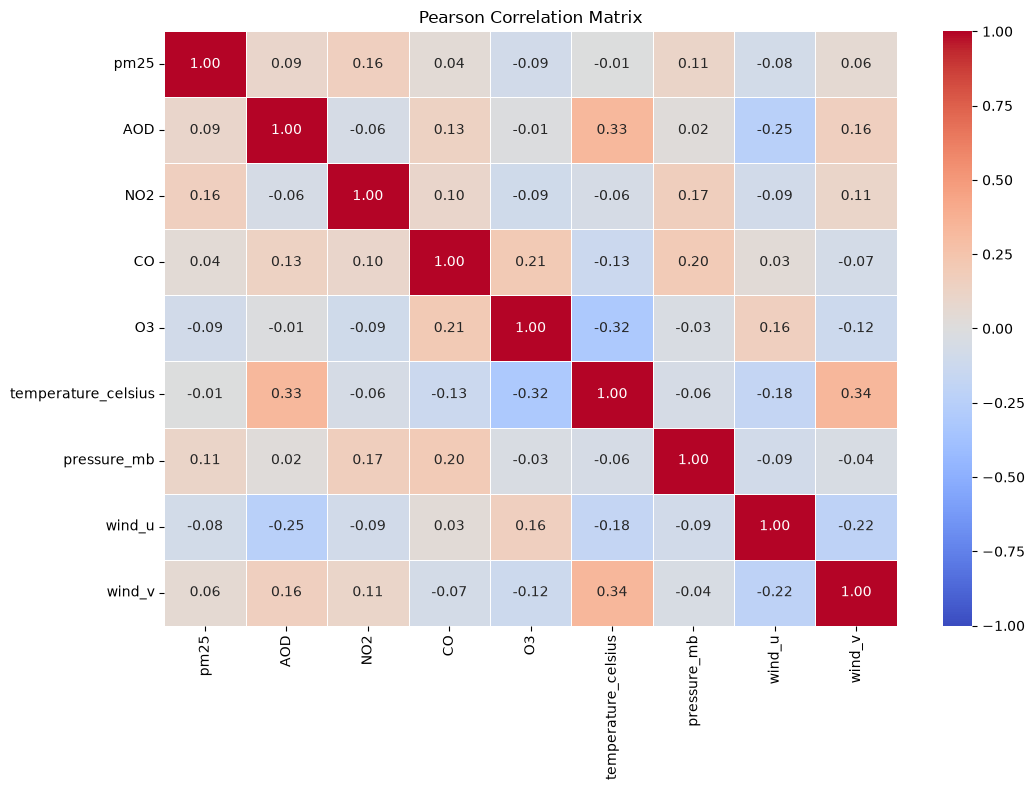

In [49]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 8))

sns.heatmap(
    pearson_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Pearson Correlation Matrix")
plt.tight_layout()
plt.show()

In [51]:
# Calculate Spearman correlation
spearman_corr = combined_cleaned[correlation_features].corr(
    method="spearman"
)

# Display results
display(spearman_corr.round(3))

,pm25,AOD,NO2,CO,O3,temperature_celsius,pressure_mb,wind_u,wind_v
pm25,1.000,0.180,0.247,0.036,-0.135,0.064,0.167,-0.164,0.097
AOD,0.180,1.000,-0.040,0.032,0.007,0.403,0.020,-0.367,0.261
NO2,0.247,-0.040,1.000,0.105,-0.057,0.065,0.143,-0.111,0.136
CO,0.036,0.032,0.105,1.000,0.278,-0.182,0.182,0.045,-0.068
O3,-0.135,0.007,-0.057,0.278,1.000,-0.299,-0.053,0.117,-0.071
temperature_celsius,0.064,0.403,0.065,-0.182,-0.299,1.000,-0.090,-0.242,0.392
pressure_mb,0.167,0.020,0.143,0.182,-0.053,-0.090,1.000,-0.111,-0.075
wind_u,-0.164,-0.367,-0.111,0.045,0.117,-0.242,-0.111,1.000,-0.207
wind_v,0.097,0.261,0.136,-0.068,-0.071,0.392,-0.075,-0.207,1.000


In [52]:
# Calculate PM2.5 threshold statistics

total = len(combined_cleaned)

above_25 = (combined_cleaned["pm25"] > 25).sum()
above_50 = (combined_cleaned["pm25"] > 50).sum()

threshold_summary = pd.DataFrame({
    "Threshold": ["> 25 µg/m³", "> 50 µg/m³"],
    "Count": [above_25, above_50],
    "Percentage (%)": [
        above_25 / total * 100,
        above_50 / total * 100
    ]
})

display(threshold_summary.round(2))

,Threshold,Count,Percentage (%)
0,> 25 µg/m³,1223,2.98
1,> 50 µg/m³,117,0.29


In [53]:
# Check date coverage

date_range = pd.date_range(
    start=combined_cleaned["date"].min(),
    end=combined_cleaned["date"].max(),
    freq="D"
)

existing_dates = pd.DatetimeIndex(
    combined_cleaned["date"].dropna().unique()
)

missing_dates = date_range.difference(existing_dates)

print("First date:", date_range.min())
print("Last date:", date_range.max())
print("Expected calendar days:", len(date_range))
print("Observed dates:", len(existing_dates))
print("Missing calendar dates:", len(missing_dates))

First date: 2016-11-25 00:00:00
Last date: 2026-04-06 00:00:00
Expected calendar days: 3420
Observed dates: 2299
Missing calendar dates: 1121


In [54]:
# Analyze temporal coverage for each station

station_coverage = []

for station, group in combined_cleaned.groupby("sensor_name"):

    dates = pd.DatetimeIndex(
        group["date"].dropna().unique()
    )

    expected_dates = pd.date_range(
        start=dates.min(),
        end=dates.max(),
        freq="D"
    )

    missing = expected_dates.difference(dates)

    station_coverage.append({
        "Station": station,
        "First date": dates.min(),
        "Last date": dates.max(),
        "Observed days": len(dates),
        "Expected days": len(expected_dates),
        "Missing days": len(missing),
        "Missing percentage (%)":
            len(missing) / len(expected_dates) * 100
    })

station_coverage_df = pd.DataFrame(station_coverage)

station_coverage_df = station_coverage_df.sort_values(
    by="Missing percentage (%)",
    ascending=False
)

display(station_coverage_df.round(2))

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_10516\2317348126.py:37: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(station_coverage_df.round(2))


,Station,First date,Last date,Observed days,Expected days,Missing days,Missing percentage (%)
17,"C. Restoy, 51, Almeria, Spain",2022-02-09,2023-05-18,21,464,443,95.47
86,VILAMARXANT,2018-01-17,2025-09-24,346,2808,2462,87.68
54,ONTINYENT,2016-11-25,2025-09-04,447,3206,2759,86.06
80,VALÈNCIA - MOLÍ DEL SOL,2016-12-02,2026-02-09,561,3357,2796,83.29
35,FR03029,2017-04-28,2020-02-12,253,1021,768,75.22
...,...,...,...,...,...,...,...
7,ALUMBRES,2025-04-27,2026-02-09,197,289,92,31.83
44,LA ALJORRA,2023-12-30,2026-02-09,528,773,245,31.69
73,TORRENT-EL VEDAT,2024-06-06,2024-09-30,89,117,28,23.93
71,Sant Francesc,2026-03-21,2026-04-06,15,17,2,11.76


In [55]:
# Compare stations before and after cleaning

original_stations = set(combined["sensor_name"].dropna().unique())

cleaned_stations = set(
    combined_cleaned["sensor_name"].dropna().unique()
)

removed_stations = original_stations - cleaned_stations

print("Original number of stations:", len(original_stations))
print("Cleaned number of stations:", len(cleaned_stations))

print("\nStations with no valid observations after cleaning:")
for station in sorted(removed_stations):
    print("-", station)

Original number of stations: 94
Cleaned number of stations: 91

Stations with no valid observations after cleaning:
- 064F
- mimiz
- testcompnex


In [56]:
# Count observations for each station

station_counts = (
    combined_cleaned
    .groupby("sensor_name")
    .size()
    .reset_index(name="Number of observations")
    .sort_values(
        by="Number of observations",
        ascending=False
    )
)

print("Number of stations:", len(station_counts))
print("\nDescriptive statistics:")

display(
    station_counts["Number of observations"]
    .describe()
    .round(2)
)

print("\n10 stations with the fewest observations:")
display(station_counts.tail(10))

print("\n10 stations with the most observations:")
display(station_counts.head(10))

Number of stations: 91

Descriptive statistics:


count      91.00
mean      450.36
std       272.66
min         4.00
25%       220.00
50%       468.00
75%       677.50
max      1042.00
Name: Number of observations, dtype: float64


10 stations with the fewest observations:


,sensor_name,Number of observations
14,Barcelona,46
69,Sant Adrià de Besòs,44
76,Terrassa,42
52,Martorell,38
41,Gibraltar,36
89,Viladecavalls,31
17,"C. Restoy, 51, Almeria, Spain",21
71,Sant Francesc,15
15,Barcelona - Camp d'en Grassot,4
64,Rosia Road,4



10 stations with the most observations:


,sensor_name,Number of observations
23,CENMO1,1042
22,CENCA1,1037
51,MOMPEAN,894
2,ALBALAT DELS TARONGERS,798
65,SAGUNT CEA,797
20,CARRANQUE,784
74,TORREVIEJA,780
5,ALGAR DE PALÀNCIA,771
12,BENICASSIM,770
4,ALCORA,761


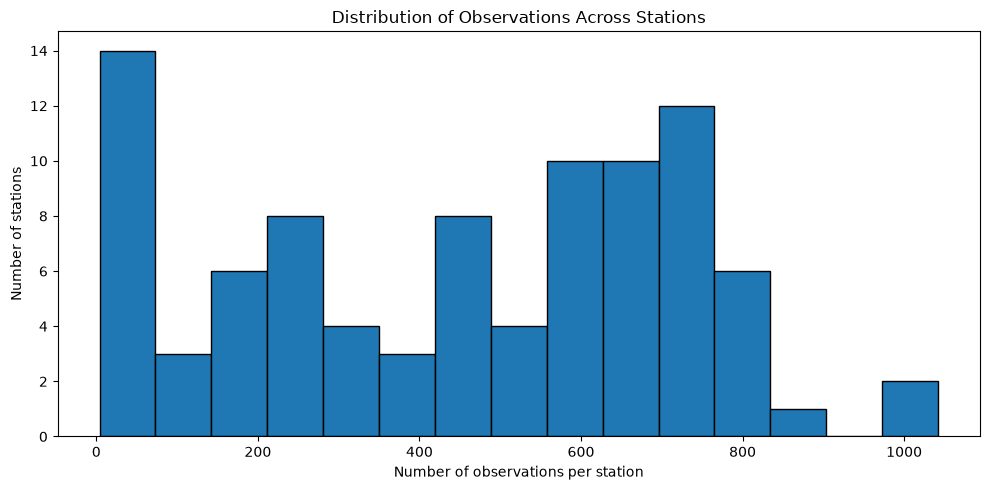

In [57]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    station_counts["Number of observations"],
    bins=15,
    edgecolor="black"
)

plt.title("Distribution of Observations Across Stations")
plt.xlabel("Number of observations per station")
plt.ylabel("Number of stations")

plt.tight_layout()
plt.show()

In [58]:
print("10 stations with the fewest observations:")
display(station_counts.tail(10))

print("10 stations with the most observations:")
display(station_counts.head(10))

10 stations with the fewest observations:


,sensor_name,Number of observations
14,Barcelona,46
69,Sant Adrià de Besòs,44
76,Terrassa,42
52,Martorell,38
41,Gibraltar,36
89,Viladecavalls,31
17,"C. Restoy, 51, Almeria, Spain",21
71,Sant Francesc,15
15,Barcelona - Camp d'en Grassot,4
64,Rosia Road,4


10 stations with the most observations:


,sensor_name,Number of observations
23,CENMO1,1042
22,CENCA1,1037
51,MOMPEAN,894
2,ALBALAT DELS TARONGERS,798
65,SAGUNT CEA,797
20,CARRANQUE,784
74,TORREVIEJA,780
5,ALGAR DE PALÀNCIA,771
12,BENICASSIM,770
4,ALCORA,761


In [59]:
# Check duplicate station-date combinations

duplicate_station_dates = combined_cleaned.duplicated(
    subset=["sensor_name", "date"],
    keep=False
)

print(
    "Number of duplicated station-date rows:",
    duplicate_station_dates.sum()
)

print(
    "Number of duplicated station-date combinations:",
    combined_cleaned.loc[
        duplicate_station_dates,
        ["sensor_name", "date"]
    ].drop_duplicates().shape[0]
)

Number of duplicated station-date rows: 4
Number of duplicated station-date combinations: 2


In [60]:
# Display duplicated station-date records

duplicates = combined_cleaned[
    combined_cleaned.duplicated(
        subset=["sensor_name", "date"],
        keep=False
    )
].sort_values(["sensor_name", "date"])

display(duplicates)

,date,datetime_utc,id,latitude,longitude,temperature_celsius,pressure_mb,wind_u,wind_v,NO2,CO,O3,AOD,pm25,sensor_name
29054,2024-08-30,2024-08-30 00:00:00,105,38.057300,-1.204700,24.053120,991.021203,-0.206704,-0.795269,0.000083,0.033897,0.143295,0.218,11.665,MOLINA DE SEGURA
29055,2024-08-30,2024-08-30 00:00:00,107,38.057373,-1.204813,24.053120,991.021203,-0.206704,-0.795269,0.000083,0.033897,0.143295,0.218,10.530,MOLINA DE SEGURA
29052,2024-08-30,2024-08-30 00:00:00,109,37.992300,-1.145900,24.680073,997.004953,-0.606647,-1.348858,0.000075,0.035093,0.143506,0.228,11.680,SAN BASILIO
29053,2024-08-30,2024-08-30 00:00:00,104,37.993611,-1.144722,24.680073,997.004953,-0.606647,-1.348858,0.000075,0.035093,0.143506,0.228,13.235,SAN BASILIO


In [61]:
# Check duplicate ID-date combinations

duplicate_id_dates = combined_cleaned.duplicated(
    subset=["id", "date"],
    keep=False
)

print(
    "Duplicated ID-date rows:",
    duplicate_id_dates.sum()
)

print(
    "Duplicated ID-date combinations:",
    combined_cleaned.loc[
        duplicate_id_dates,
        ["id", "date"]
    ].drop_duplicates().shape[0]
)

Duplicated ID-date rows: 0
Duplicated ID-date combinations: 0


In [62]:
# Calculate time intervals between consecutive observations

combined_sorted = combined_cleaned.sort_values(
    ["id", "date"]
).copy()

combined_sorted["days_since_previous"] = (
    combined_sorted.groupby("id")["date"]
    .diff()
    .dt.days
)

print("Distribution of time intervals between observations:")
display(
    combined_sorted["days_since_previous"]
    .value_counts()
    .sort_index()
    .head(15)
)

Distribution of time intervals between observations:


days_since_previous
1.0     27259
2.0      6497
3.0      3005
4.0      1407
5.0       825
6.0       572
7.0       387
8.0       147
9.0        83
10.0       89
11.0       75
12.0       37
13.0       25
14.0       60
15.0       30
Name: count, dtype: int64

In [63]:
# Calculate interval percentages

interval_counts = (
    combined_sorted["days_since_previous"]
    .value_counts()
    .sort_index()
)

interval_summary = pd.DataFrame({
    "Number of intervals": interval_counts,
    "Percentage (%)": (
        interval_counts / interval_counts.sum() * 100
    )
})

display(interval_summary.head(15).round(2))

# Overall daily vs non-daily intervals

total_intervals = interval_counts.sum()
daily_intervals = interval_counts.get(1, 0)

print("Total intervals:", total_intervals)
print("Daily intervals:", daily_intervals)
print("Non-daily intervals:", total_intervals - daily_intervals)
print(
    "Daily interval percentage:",
    round(daily_intervals / total_intervals * 100, 2),
    "%"
)

,Number of intervals,Percentage (%)
days_since_previous,,
1.0,27259,66.67
2.0,6497,15.89
3.0,3005,7.35
4.0,1407,3.44
5.0,825,2.02
6.0,572,1.40
7.0,387,0.95
8.0,147,0.36
9.0,83,0.20


Total intervals: 40888
Daily intervals: 27259
Non-daily intervals: 13629
Daily interval percentage: 66.67 %


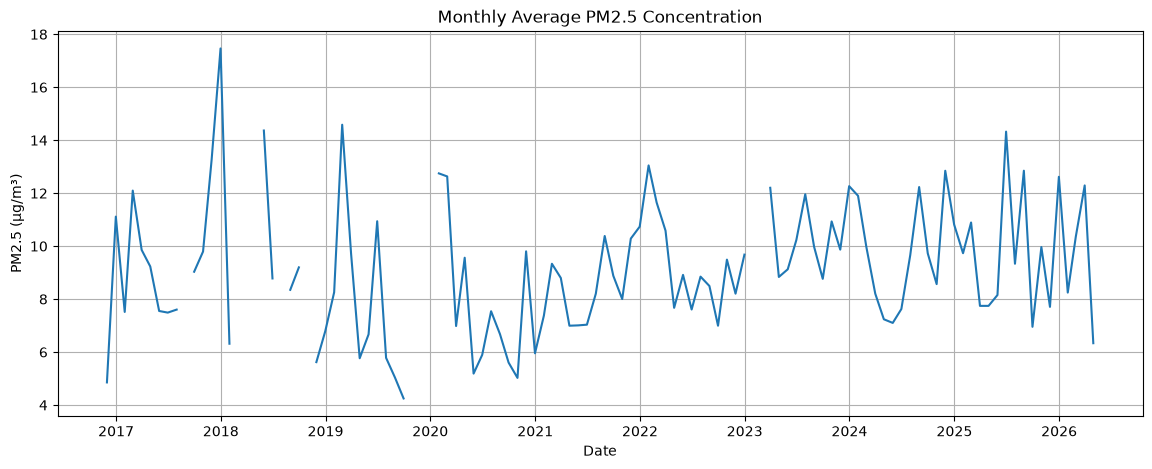

In [64]:
# Monthly average PM2.5
monthly_pm25 = (
    combined_cleaned
    .set_index("date")["pm25"]
    .resample("ME")
    .mean()
)

# Plot monthly evolution
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(monthly_pm25.index, monthly_pm25.values)
plt.title("Monthly Average PM2.5 Concentration")
plt.xlabel("Date")
plt.ylabel("PM2.5 (µg/m³)")
plt.grid(True)
plt.show()

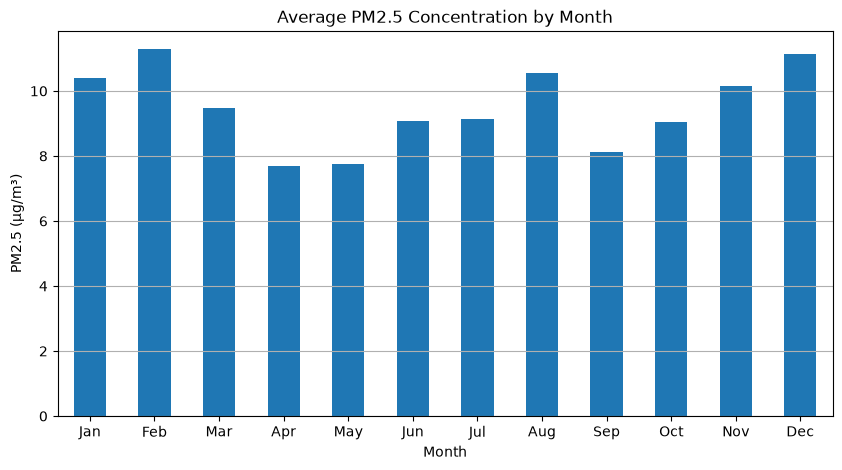

In [65]:
# Extract calendar month
combined_cleaned["month"] = combined_cleaned["date"].dt.month

# Calculate average PM2.5 for each month across all years
seasonal_pm25 = (
    combined_cleaned
    .groupby("month")["pm25"]
    .mean()
)

plt.figure(figsize=(10, 5))
seasonal_pm25.plot(kind="bar")

plt.title("Average PM2.5 Concentration by Month")
plt.xlabel("Month")
plt.ylabel("PM2.5 (µg/m³)")
plt.xticks(
    range(12),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
    rotation=0
)
plt.grid(axis="y")
plt.show()

date
2016-12-31    10.89
2017-12-31     9.46
2018-12-31     7.88
2019-12-31     8.65
2020-12-31     7.55
2021-12-31     8.85
2022-12-31     9.62
2023-12-31    10.22
2024-12-31     9.61
2025-12-31     9.92
2026-12-31     9.90
Freq: YE-DEC, Name: pm25, dtype: float64

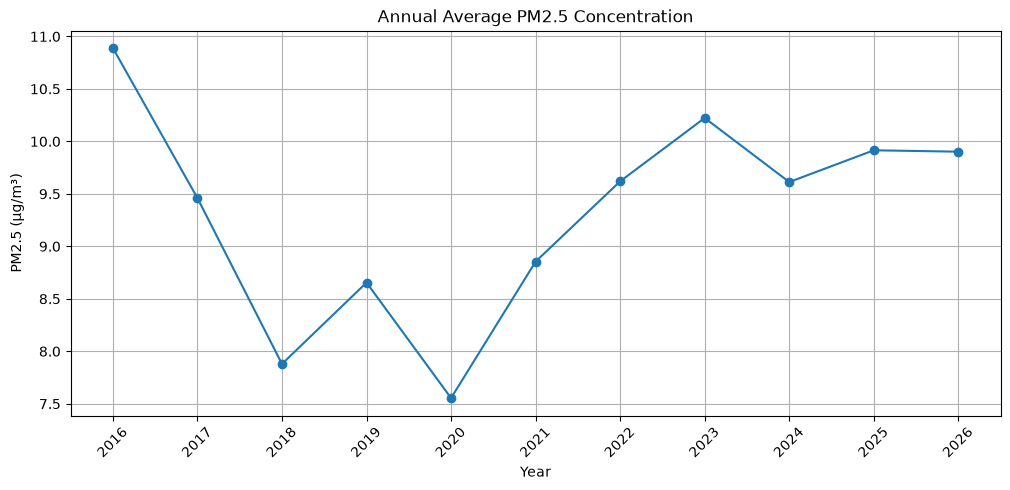

In [66]:
# Calculate annual average PM2.5
annual_pm25 = (
    combined_cleaned
    .set_index("date")["pm25"]
    .resample("YE")
    .mean()
)

# Display annual values
display(annual_pm25.round(2))

# Plot annual evolution
plt.figure(figsize=(12, 5))
plt.plot(
    annual_pm25.index.year,
    annual_pm25.values,
    marker="o"
)

plt.title("Annual Average PM2.5 Concentration")
plt.xlabel("Year")
plt.ylabel("PM2.5 (µg/m³)")
plt.xticks(annual_pm25.index.year, rotation=45)
plt.grid(True)
plt.show()

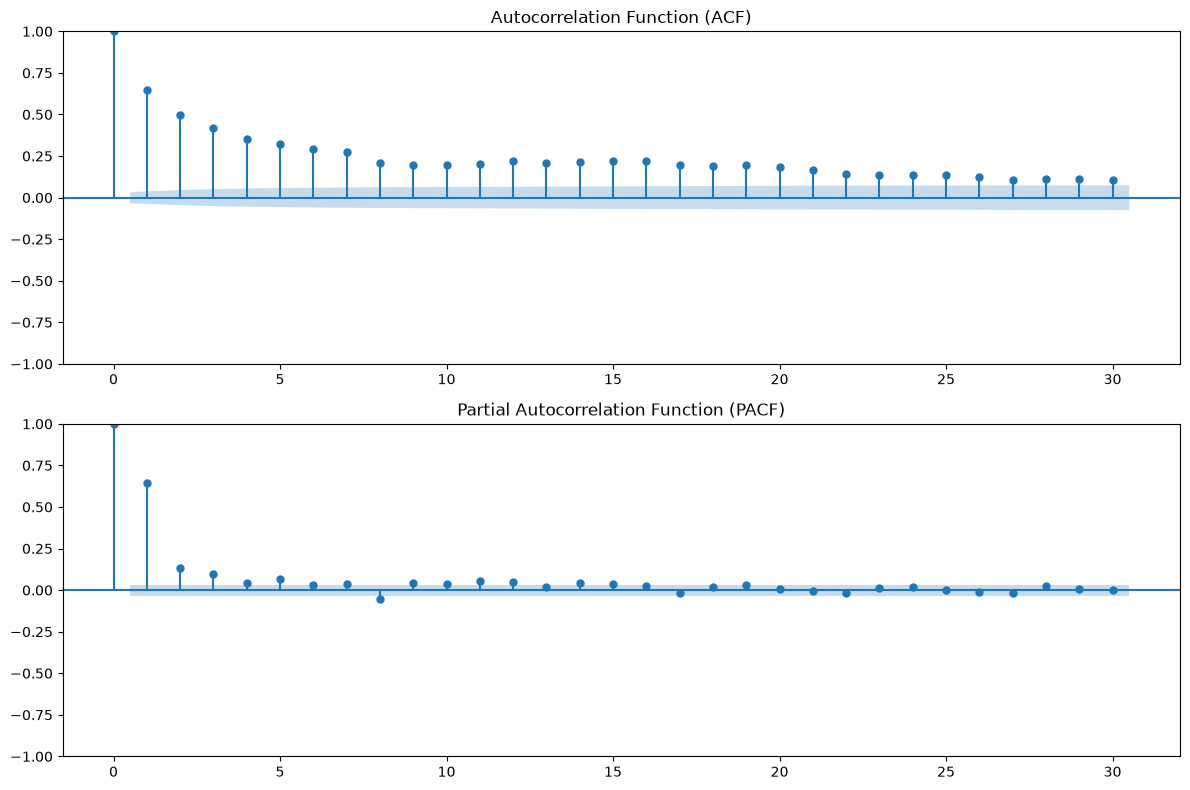

In [67]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

# 1. Calculate daily average PM2.5
daily_pm25 = (
    combined_cleaned
    .groupby("date")["pm25"]
    .mean()
    .sort_index()
)

# 2. Create a complete daily time series
daily_pm25 = daily_pm25.asfreq("D")

# 3. Interpolate missing dates for this exploratory analysis
daily_pm25 = daily_pm25.interpolate(method="time", limit_area="inside")

# 4. Plot ACF and PACF
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

plot_acf(
    daily_pm25.dropna(),
    lags=30,
    ax=axes[0]
)
axes[0].set_title("Autocorrelation Function (ACF)")

plot_pacf(
    daily_pm25.dropna(),
    lags=30,
    method="ywm",
    ax=axes[1]
)
axes[1].set_title("Partial Autocorrelation Function (PACF)")

plt.tight_layout()
plt.show()

Lag (days),0,1,2,3,4,5,6,7
Feature,,,,,,,,
AOD,0.150,0.053,-0.008,-0.050,-0.064,-0.067,-0.080,-0.089
CO,0.049,0.080,0.092,0.083,0.082,0.072,0.039,0.032
NO2,0.313,0.295,0.222,0.184,0.115,0.065,0.070,0.083
O3,-0.111,-0.115,-0.082,-0.061,-0.045,-0.048,-0.048,-0.056
pressure_mb,0.249,0.267,0.266,0.238,0.190,0.188,0.126,0.135
temperature_celsius,-0.127,-0.153,-0.164,-0.158,-0.171,-0.161,-0.164,-0.166
wind_u,-0.163,-0.229,-0.203,-0.159,-0.093,-0.054,-0.025,-0.000
wind_v,0.086,0.005,-0.064,-0.119,-0.112,-0.122,-0.103,-0.096


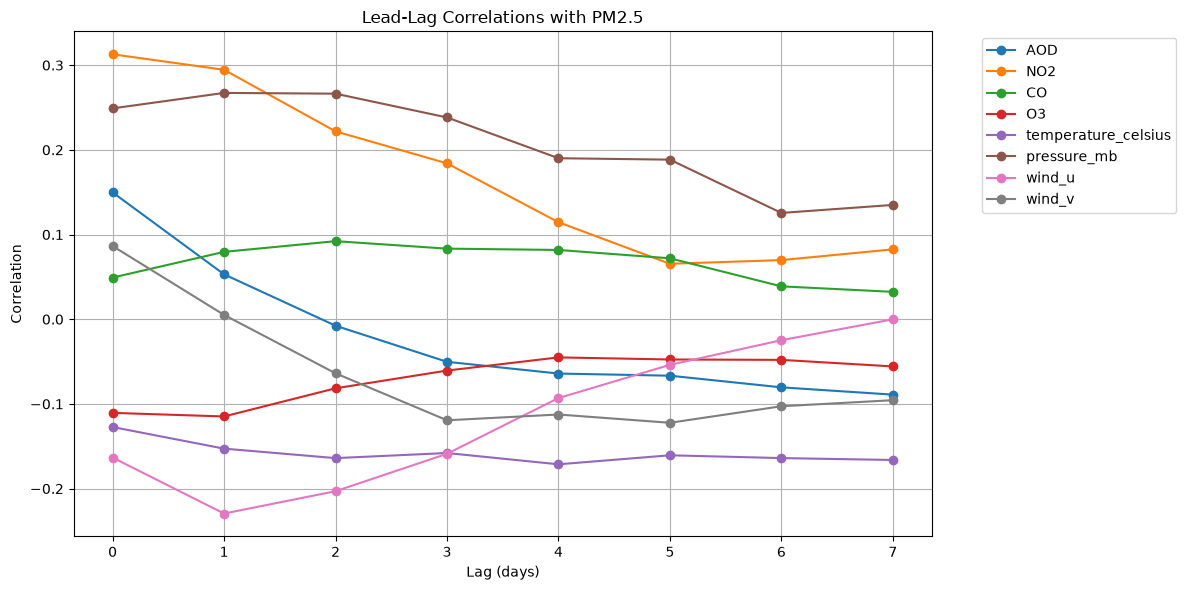

In [68]:
import pandas as pd
import matplotlib.pyplot as plt

# Variables to analyze
features = [
    "AOD", "NO2", "CO", "O3",
    "temperature_celsius", "pressure_mb",
    "wind_u", "wind_v"
]

# Calculate daily averages
daily_data = (
    combined_cleaned
    .groupby("date")[["pm25"] + features]
    .mean()
    .sort_index()
    .asfreq("D")
)

# Calculate correlations for lags from 0 to 7 days
results = []

for feature in features:
    for lag in range(8):
        correlation = daily_data["pm25"].corr(
            daily_data[feature].shift(lag)
        )

        results.append({
            "Feature": feature,
            "Lag (days)": lag,
            "Correlation": correlation
        })

lag_correlations = pd.DataFrame(results)

# Display results
display(
    lag_correlations
    .pivot(index="Feature", columns="Lag (days)", values="Correlation")
    .round(3)
)

# Plot correlations
plt.figure(figsize=(12, 6))

for feature in features:
    subset = lag_correlations[
        lag_correlations["Feature"] == feature
    ]
    plt.plot(
        subset["Lag (days)"],
        subset["Correlation"],
        marker="o",
        label=feature
    )

plt.title("Lead-Lag Correlations with PM2.5")
plt.xlabel("Lag (days)")
plt.ylabel("Correlation")
plt.xticks(range(8))
plt.grid(True)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [70]:
# Create a copy of the cleaned dataset
model_df = combined_cleaned.copy()

# Extract temporal features
model_df["year"] = model_df["date"].dt.year
model_df["month"] = model_df["date"].dt.month
model_df["day_of_year"] = model_df["date"].dt.dayofyear

# Define target
y = model_df["pm25"].copy()

# Define numerical features
features = [
    "AOD",
    "NO2",
    "CO",
    "O3",
    "temperature_celsius",
    "pressure_mb",
    "wind_u",
    "wind_v",
    "latitude",
    "longitude",
    "year",
    "month",
    "day_of_year"
]

X = model_df[features].copy()

# Check dimensions
print("Dataset:", model_df.shape)
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nMissing values in X:")
print(X.isnull().sum())

print("\nMissing values in y:", y.isnull().sum())

Dataset: (40983, 18)
X shape: (40983, 13)
y shape: (40983,)

Missing values in X:
AOD                       0
NO2                    2407
CO                     2407
O3                     2448
temperature_celsius       0
pressure_mb               0
wind_u                    0
wind_v                    0
latitude                  0
longitude                 0
year                      0
month                     0
day_of_year               0
dtype: int64

Missing values in y: 0


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_10516\3662731932.py:7: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  model_df["day_of_year"] = model_df["date"].dt.dayofyear


In [71]:
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# Variables with missing values
missing_features = ["NO2", "CO", "O3"]

# Other numerical features
other_features = [
    col for col in X.columns
    if col not in missing_features
]

# Pipeline for variables with missing values
missing_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True))
])

# Pipeline for other numerical variables
other_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer([
    ("missing", missing_pipeline, missing_features),
    ("other", other_pipeline, other_features)
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [73]:
# Find the chronological cutoff date
unique_dates = sorted(model_df["date"].unique())

split_date = unique_dates[int(len(unique_dates) * 0.80)]

# Strict chronological split
train_mask = model_df["date"] < split_date
test_mask = model_df["date"] >= split_date

X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

print("Split date:", split_date)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print("Training last date:", model_df.loc[train_mask, "date"].max())
print("Testing first date:", model_df.loc[test_mask, "date"].min())

Split date: 2024-12-08 00:00:00
Training observations: 30651
Testing observations: 10332
Training last date: 2024-12-07 00:00:00
Testing first date: 2024-12-08 00:00:00


In [74]:
# Fit preprocessing only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data without refitting
X_test_processed = preprocessor.transform(X_test)

print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)

print("Missing values after preprocessing:")
print("Train:", __import__("numpy").isnan(X_train_processed).sum())
print("Test:", __import__("numpy").isnan(X_test_processed).sum())

Training data shape: (30651, 16)
Testing data shape: (10332, 16)
Missing values after preprocessing:
Train: 0
Test: 0


In [75]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd
import time

# Define models
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(
        random_state=42,
        max_depth=15
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    )
}

results = []

# Train and evaluate models
for name, model in models.items():

    start = time.time()

    model.fit(X_train_processed, y_train)

    predictions = model.predict(X_test_processed)

    elapsed_time = time.time() - start

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Runtime (seconds)": elapsed_time
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,MAE,RMSE,R2,Runtime (seconds)
0,Linear Regression,5.1221,7.2235,0.0512,0.0367
1,Decision Tree,5.5205,9.7710,-0.7361,0.5781
2,Random Forest,4.7900,7.6720,-0.0703,10.5466


In [76]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Baseline model
baseline = DummyRegressor(strategy="mean")

baseline.fit(X_train_processed, y_train)

baseline_predictions = baseline.predict(X_test_processed)

# Evaluation
baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)
baseline_r2 = r2_score(y_test, baseline_predictions)

print("Baseline Results")
print("----------------")
print("MAE:", round(baseline_mae, 4))
print("RMSE:", round(baseline_rmse, 4))
print("R2:", round(baseline_r2, 4))

Baseline Results
----------------
MAE: 5.0546
RMSE: 7.4436
R2: -0.0075


In [77]:
import pandas as pd

# Sort data by sensor ID and date
df_temporal = combined_cleaned.copy()
df_temporal["date"] = pd.to_datetime(df_temporal["date"])
df_temporal = df_temporal.sort_values(["id", "date"])

# Check duplicate ID-date combinations
duplicates = df_temporal.duplicated(
    subset=["id", "date"]
).sum()

print("Duplicate ID-date combinations:", duplicates)

# Check station names associated with each ID
id_station_check = (
    df_temporal.groupby("id")["sensor_name"]
    .nunique()
)

print("IDs associated with multiple station names:",
      (id_station_check > 1).sum())

# Create an independent daily timeline for each ID
station_daily_list = []

for sensor_id, group in df_temporal.groupby("id"):

    group = group.set_index("date").sort_index()

    full_dates = pd.date_range(
        start=group.index.min(),
        end=group.index.max(),
        freq="D"
    )

    daily_group = group.reindex(full_dates)
    daily_group.index.name = "date"

    # Restore the sensor ID
    daily_group["id"] = sensor_id

    station_daily_list.append(daily_group)

# Combine all independent timelines
station_daily = pd.concat(station_daily_list)

station_daily = (
    station_daily
    .reset_index()
    .sort_values(["id", "date"])
    .reset_index(drop=True)
)

print("\nDaily timeline created successfully.")
print("Original observations:", len(df_temporal))
print("Timeline observations:", len(station_daily))
print("Number of IDs:", station_daily["id"].nunique())

display(station_daily.head())

Duplicate ID-date combinations: 0
IDs associated with multiple station names: 0

Daily timeline created successfully.
Original observations: 40983
Timeline observations: 95540
Number of IDs: 95


,date,datetime_utc,id,latitude,longitude,temperature_celsius,pressure_mb,wind_u,wind_v,NO2,CO,O3,AOD,pm25,sensor_name,month
0,2016-12-07,2016-12-07 00:00:00,0,38.454722,-0.803333,9.768313,965.439025,-0.523074,-1.949791,NaN,NaN,NaN,0.144,12.111111,ELDA-LACY,12.0
1,2016-12-08,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2016-12-09,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2016-12-10,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2016-12-11,2016-12-11 00:00:00,0,38.454722,-0.803333,10.490162,961.187736,0.494681,-0.604369,NaN,NaN,NaN,0.043,16.062500,ELDA-LACY,12.0


In [78]:
# Calculate temporal coverage for each ID
coverage = (
    station_daily.groupby("id")
    .agg(
        sensor_name=("sensor_name", "first"),
        first_date=("date", "min"),
        last_date=("date", "max"),
        total_days=("date", "count"),
        observed_pm25=("pm25", "count")
    )
)

coverage["missing_days"] = (
    coverage["total_days"] - coverage["observed_pm25"]
)

coverage["missing_percentage"] = (
    coverage["missing_days"] / coverage["total_days"] * 100
)

coverage["coverage_percentage"] = (
    coverage["observed_pm25"] / coverage["total_days"] * 100
)

coverage = coverage.sort_values("coverage_percentage")

display(coverage.round(2))

print("\nNumber of IDs:", len(coverage))
print("IDs with fewer than 30 observations:",
      (coverage["observed_pm25"] < 30).sum())

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_10516\827358529.py:27: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(coverage.round(2))


,sensor_name,first_date,last_date,total_days,observed_pm25,missing_days,missing_percentage,coverage_percentage
id,,,,,,,,
95,"C. Restoy, 51, Almeria, Spain",2022-02-09,2023-05-18,464,21,443,95.47,4.53
10,VILAMARXANT,2018-01-17,2025-09-24,2808,346,2462,87.68,12.32
1,ONTINYENT,2016-11-25,2025-09-04,3206,447,2759,86.06,13.94
7,VALÈNCIA - MOLÍ DEL SOL,2016-12-02,2026-02-09,3357,561,2796,83.29,16.71
69,FR03029,2017-04-28,2020-02-12,1021,253,768,75.22,24.78
...,...,...,...,...,...,...,...,...
105,MOLINA DE SEGURA,2024-01-28,2024-08-30,216,149,67,31.02,68.98
84,LA ALJORRA,2023-12-30,2024-08-28,243,169,74,30.45,69.55
9,TORRENT-EL VEDAT,2024-06-06,2024-09-30,117,89,28,23.93,76.07



Number of IDs: 95
IDs with fewer than 30 observations: 4


In [79]:
# Summary of observation counts per ID
print("Observation count statistics:")
display(coverage["observed_pm25"].describe())

# Count IDs under different observation thresholds
for threshold in [30, 50, 100, 200]:
    count = (coverage["observed_pm25"] < threshold).sum()
    print(f"IDs with fewer than {threshold} observations: {count}")

# Identify IDs with fewer than 100 observations
low_coverage_ids = coverage[
    coverage["observed_pm25"] < 100
]

print("\nIDs with fewer than 100 observations:")
display(low_coverage_ids.round(2))

# Check station names associated with multiple IDs
multiple_ids = (
    df_temporal.groupby("sensor_name")["id"]
    .nunique()
)

print(
    "\nStation names associated with multiple IDs:",
    (multiple_ids > 1).sum()
)

Observation count statistics:


count      95.000000
mean      431.400000
std       266.997227
min         4.000000
25%       205.500000
50%       442.000000
75%       646.500000
max      1042.000000
Name: observed_pm25, dtype: float64

IDs with fewer than 30 observations: 4
IDs with fewer than 50 observations: 11
IDs with fewer than 100 observations: 15
IDs with fewer than 200 observations: 23

IDs with fewer than 100 observations:


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_10516\2522484584.py:16: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(low_coverage_ids.round(2))


,sensor_name,first_date,last_date,total_days,observed_pm25,missing_days,missing_percentage,coverage_percentage
id,,,,,,,,
95,"C. Restoy, 51, Almeria, Spain",2022-02-09,2023-05-18,464,21,443,95.47,4.53
59,Viladecavalls,2025-12-28,2026-04-06,100,31,69,69.00,31.00
31,Rosia Road,2024-02-02,2024-02-13,12,4,8,66.67,33.33
40,BARCELONA (PARC DE LA VALL D'HEBRON),2025-09-10,2026-01-22,135,62,73,54.07,45.93
48,Martorell,2026-01-15,2026-04-06,82,38,44,53.66,46.34
46,Terrassa,2026-01-15,2026-04-06,82,42,40,48.78,51.22
60,Barcelona,2026-01-07,2026-04-05,89,46,43,48.31,51.69
42,Sant Adrià de Besòs,2026-01-15,2026-04-06,82,44,38,46.34,53.66
56,"Avinguda Meridiana, Sagerra",2025-08-31,2025-12-03,95,52,43,45.26,54.74



Station names associated with multiple IDs: 4


In [2]:
import pandas as pd

In [3]:
pm25 = pd.read_csv("../dataset/pm25.csv")
gee = pd.read_csv("../dataset/gee_features_daily.csv")
combined = pd.read_csv("../dataset/combined_gee_pm25.csv")

print("PM2.5:", pm25.shape)
print(pm25.columns.tolist())

print("\nGEE:", gee.shape)
print(gee.columns.tolist())

print("\nCOMBINED:", combined.shape)
print(combined.columns.tolist())

PM2.5: (88041, 5)
['date', 'latitude', 'longitude', 'pm25', 'sensor_name']

GEE: (164208, 13)
['date', 'datetime_utc', 'id', 'lat', 'lon', 'temperature_celsius', 'pressure_mb', 'wind_u', 'wind_v', 'NO2', 'CO', 'O3', 'AOD']

COMBINED: (41718, 15)
['date', 'datetime_utc', 'id', 'latitude', 'longitude', 'temperature_celsius', 'pressure_mb', 'wind_u', 'wind_v', 'NO2', 'CO', 'O3', 'AOD', 'pm25', 'sensor_name']


In [4]:
# Convert dates to datetime
pm25["date"] = pd.to_datetime(pm25["date"])
gee["date"] = pd.to_datetime(gee["date"])
combined["date"] = pd.to_datetime(combined["date"])

# Date ranges
print("PM2.5 date range:")
print(pm25["date"].min(), "to", pm25["date"].max())

print("\nGEE date range:")
print(gee["date"].min(), "to", gee["date"].max())

print("\nCombined date range:")
print(combined["date"].min(), "to", combined["date"].max())

# Unique stations and IDs
print("\nPM2.5 unique station names:", pm25["sensor_name"].nunique())
print("GEE unique IDs:", gee["id"].nunique())
print("Combined unique IDs:", combined["id"].nunique())

# Duplicate checks
print("\nPM2.5 duplicate date/location/name:",
      pm25.duplicated(["date", "latitude", "longitude", "sensor_name"]).sum())

print("GEE duplicate date/ID:",
      gee.duplicated(["date", "id"]).sum())

print("Combined duplicate date/ID:",
      combined.duplicated(["date", "id"]).sum())

# Display examples
print("\nPM2.5 sample:")
display(pm25.head(3))

print("\nGEE sample:")
display(gee.head(3))

print("\nCombined sample:")
display(combined.head(3))

PM2.5 date range:
2016-11-21 00:00:00 to 2026-04-16 00:00:00

GEE date range:
2016-11-21 00:00:00 to 2026-04-06 00:00:00

Combined date range:
2016-11-25 00:00:00 to 2026-04-06 00:00:00

PM2.5 unique station names: 125
GEE unique IDs: 100
Combined unique IDs: 98

PM2.5 duplicate date/location/name: 0
GEE duplicate date/ID: 0
Combined duplicate date/ID: 0

PM2.5 sample:


,date,latitude,longitude,pm25,sensor_name
0,2016-11-21,38.788056,-0.697222,4.0,ONTINYENT
1,2016-11-21,39.456111,-0.375833,3.0,VALÈNCIA-PISTA DE SILLA
2,2016-11-21,39.480300,-0.336400,2.0,VALÈNCIA-POLITÈCNIC



GEE sample:


,date,datetime_utc,id,lat,lon,temperature_celsius,pressure_mb,wind_u,wind_v,NO2,CO,O3,AOD
0,2016-11-21,2016-11-21 00:00:00,90,39.235833,9.115000,15.842538,994.344313,-2.613506,2.663921,NaN,NaN,NaN,0.207
1,2016-11-21,2016-11-21 00:00:00,91,39.260556,9.136389,15.842538,994.344313,-2.613506,2.663921,NaN,NaN,NaN,0.207
2,2016-11-22,2016-11-22 00:00:00,28,36.203880,-5.383710,13.119320,989.320581,1.555070,0.348089,NaN,NaN,NaN,0.277



Combined sample:


,date,datetime_utc,id,latitude,longitude,temperature_celsius,pressure_mb,wind_u,wind_v,NO2,CO,O3,AOD,pm25,sensor_name
0,2016-11-25,2016-11-25 00:00:00,1,38.788056,-0.697222,6.493180,946.288660,0.230240,0.735303,NaN,NaN,NaN,0.111,2.750000,ONTINYENT
1,2016-11-25,2016-11-25 00:00:00,36,39.945278,-0.056389,9.251236,993.626994,0.783218,-0.592618,NaN,NaN,NaN,0.022,11.666667,ALMASSORA-C. P. OCHANDO
2,2016-11-30,2016-11-30 00:00:00,35,40.051944,-0.189722,10.044782,981.911432,-2.211047,-1.568971,NaN,NaN,NaN,0.238,2.400000,ALCORA


In [6]:
# Compare GEE IDs with Combined IDs
gee_ids = set(gee["id"].unique())
combined_ids = set(combined["id"].unique())

missing_ids = gee_ids - combined_ids
extra_ids = combined_ids - gee_ids

print("GEE IDs:", len(gee_ids))
print("Combined IDs:", len(combined_ids))

print("\nIDs present in GEE but absent from Combined:")
print(sorted(missing_ids))

print("\nIDs present in Combined but absent from GEE:")
print(sorted(extra_ids))

# Inspect missing IDs
print("\nDetails of missing GEE IDs:")
display(
    gee[gee["id"].isin(missing_ids)]
    .groupby("id")
    .agg(
        observations=("date", "count"),
        first_date=("date", "min"),
        last_date=("date", "max"),
        latitude=("lat", "mean"),
        longitude=("lon", "mean")
    ).round(4)
)

GEE IDs: 100
Combined IDs: 98

IDs present in GEE but absent from Combined:
[np.int64(58), np.int64(75)]

IDs present in Combined but absent from GEE:
[]

Details of missing GEE IDs:


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_5880\599047512.py:28: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ).round(4)


,observations,first_date,last_date,latitude,longitude
id,,,,,
58,1606,2016-11-25,2026-04-06,41.5459,1.9461
75,1476,2016-11-23,2026-04-06,43.2865,5.3802


In [7]:
import numpy as np

# Average coordinates and date ranges for PM2.5 stations
pm25_stations = (
    pm25.groupby("sensor_name")
    .agg(
        latitude=("latitude", "mean"),
        longitude=("longitude", "mean"),
        first_date=("date", "min"),
        last_date=("date", "max"),
        observations=("pm25", "count")
    )
    .reset_index()
)

# Examine IDs 58 and 75
for gee_id in [58, 75]:

    gee_station = gee[gee["id"] == gee_id]

    gee_lat = gee_station["lat"].mean()
    gee_lon = gee_station["lon"].mean()

    gee_first = gee_station["date"].min()
    gee_last = gee_station["date"].max()

    candidates = pm25_stations.copy()

    # Approximate geographic distance in degrees
    candidates["distance_deg"] = np.sqrt(
        (candidates["latitude"] - gee_lat) ** 2 +
        (candidates["longitude"] - gee_lon) ** 2
    )

    # Check overlapping dates
    candidates["date_overlap"] = (
        (candidates["first_date"] <= gee_last) &
        (candidates["last_date"] >= gee_first)
    )

    candidates = candidates[
        (candidates["distance_deg"] <= 0.25) &
        (candidates["date_overlap"])
    ].sort_values("distance_deg")

    print(f"\nGEE ID: {gee_id}")
    print(f"GEE coordinates: ({gee_lat:.4f}, {gee_lon:.4f})")
    print("Nearby PM2.5 stations:")

    display(candidates.round(4))


GEE ID: 58
GEE coordinates: (41.5459, 1.9461)
Nearby PM2.5 stations:


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_5880\3782381827.py:50: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(candidates.round(4))


,sensor_name,latitude,longitude,first_date,last_date,observations,distance_deg,date_overlap
117,Viladecavalls,41.5461,1.9462,2025-12-19,2026-04-16,75,0.0002,True
104,Terrassa,41.5561,2.0074,2026-01-13,2026-04-15,87,0.0621,True
77,Martorell,41.4754,1.9212,2026-01-13,2026-04-15,88,0.0748,True
98,Sant Andreu de la Barca,41.4508,1.9749,2023-03-30,2026-04-15,467,0.0993,True
99,Sant Francesc,41.4778,2.0876,2026-03-21,2026-04-16,27,0.1570,True
86,Polinya,41.5577,2.1587,2025-08-20,2026-04-16,240,0.2129,True
16,BARCELONA (PARC DE LA VALL D'HEBRON),41.4261,2.1480,2025-09-10,2026-01-22,135,0.2347,True
100,Santa Perpètua de Mogoda,41.5267,2.1838,2025-02-21,2026-04-15,412,0.2384,True
63,"Hospitalet de Llobregat, l'",41.3705,2.1150,2026-01-13,2026-04-15,90,0.2435,True
38,Can Bruixa,41.3837,2.1319,2024-10-20,2025-09-11,109,0.2466,True



GEE ID: 75
GEE coordinates: (43.2865, 5.3802)
Nearby PM2.5 stations:


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_5880\3782381827.py:50: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(candidates.round(4))


,sensor_name,latitude,longitude,first_date,last_date,observations,distance_deg,date_overlap
123,réunion capt'air citoyen,43.2865,5.3802,2023-04-04,2023-04-04,1,0.0000,True
124,testcompnex,43.2868,5.3791,2022-05-19,2022-07-19,6,0.0012,True
0,064F,43.2871,5.3789,2022-04-04,2022-04-04,1,0.0015,True
121,mimiz,43.2890,5.3746,2023-12-20,2024-02-11,13,0.0062,True
70,MARSEILLE RABATAU,43.2764,5.3974,2024-01-28,2026-04-13,752,0.0199,True
50,FR03006,43.2763,5.3977,2017-04-27,2020-02-19,844,0.0202,True
69,MARSEILLE 5 AVENUES,43.3053,5.3947,2024-01-28,2026-04-16,787,0.0237,True
54,FR03043,43.3061,5.3958,2017-04-27,2020-02-20,835,0.0250,True
10,AMU_St Jerome_road,43.3371,5.4107,2024-04-24,2024-12-31,251,0.0591,True
9,AMU_St Jerome_building,43.3372,5.4107,2024-04-24,2024-12-18,238,0.0592,True


In [8]:
for gee_id in [58, 75]:

    gee_station = gee[gee["id"] == gee_id]

    gee_lat = gee_station["lat"].mean()
    gee_lon = gee_station["lon"].mean()

    candidates = pm25_stations.copy()

    candidates["distance_deg"] = np.sqrt(
        (candidates["latitude"] - gee_lat) ** 2 +
        (candidates["longitude"] - gee_lon) ** 2
    )

    candidates = candidates.sort_values("distance_deg")

    print(f"\nGEE ID: {gee_id}")
    display(candidates.head(5).round(4))


GEE ID: 58


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_5880\2223639321.py:18: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(candidates.head(5).round(4))


,sensor_name,latitude,longitude,first_date,last_date,observations,distance_deg
117,Viladecavalls,41.5461,1.9462,2025-12-19,2026-04-16,75,0.0002
104,Terrassa,41.5561,2.0074,2026-01-13,2026-04-15,87,0.0621
77,Martorell,41.4754,1.9212,2026-01-13,2026-04-15,88,0.0748
98,Sant Andreu de la Barca,41.4508,1.9749,2023-03-30,2026-04-15,467,0.0993
99,Sant Francesc,41.4778,2.0876,2026-03-21,2026-04-16,27,0.1570



GEE ID: 75


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_5880\2223639321.py:18: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(candidates.head(5).round(4))


,sensor_name,latitude,longitude,first_date,last_date,observations,distance_deg
123,réunion capt'air citoyen,43.2865,5.3802,2023-04-04,2023-04-04,1,0.0000
124,testcompnex,43.2868,5.3791,2022-05-19,2022-07-19,6,0.0012
0,064F,43.2871,5.3789,2022-04-04,2022-04-04,1,0.0015
121,mimiz,43.2890,5.3746,2023-12-20,2024-02-11,13,0.0062
70,MARSEILLE RABATAU,43.2764,5.3974,2024-01-28,2026-04-13,752,0.0199


In [9]:
for gee_id in [58, 75]:

    gee_part = gee[gee["id"] == gee_id].copy()

    # Match observations on the exact same date
    matches = gee_part.merge(
        pm25,
        on="date",
        how="inner",
        suffixes=("_gee", "_pm25")
    )

    # Calculate geographic distance
    matches["distance_deg"] = np.sqrt(
        (matches["lat"] - matches["latitude"]) ** 2 +
        (matches["lon"] - matches["longitude"]) ** 2
    )

    # Keep geographically close observations
    close_matches = matches[matches["distance_deg"] <= 0.25]

    summary = (
        close_matches.groupby("sensor_name")
        .agg(
            matched_observations=("date", "count"),
            matched_dates=("date", "nunique"),
            first_match=("date", "min"),
            last_match=("date", "max"),
            mean_distance=("distance_deg", "mean"),
            min_distance=("distance_deg", "min")
        )
        .sort_values("matched_dates", ascending=False)
    )

    print(f"\n===== GEE ID {gee_id} =====")
    print("Same-date geographic matches:", len(close_matches))
    display(summary.round(4))


===== GEE ID 58 =====
Same-date geographic matches: 1519


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_5880\1344789589.py:37: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(summary.round(4))


,matched_observations,matched_dates,first_match,last_match,mean_distance,min_distance
sensor_name,,,,,,
Barcelona,580,580,2023-04-01,2026-04-06,0.2317,0.2317
Sant Andreu de la Barca,277,277,2023-04-01,2026-04-06,0.0993,0.0993
Santa Perpètua de Mogoda,237,237,2025-02-26,2026-04-06,0.2384,0.2384
Polinya,122,122,2025-08-21,2026-04-06,0.2129,0.2129
Can Bruixa,70,70,2024-10-20,2025-09-11,0.2466,0.2466
BARCELONA (PARC DE LA VALL D'HEBRON),64,64,2025-09-10,2026-01-22,0.2347,0.2347
"Hospitalet de Llobregat, l'",42,42,2026-01-15,2026-04-06,0.2435,0.2435
Martorell,41,41,2026-01-15,2026-04-06,0.0748,0.0748
Terrassa,40,40,2026-01-15,2026-04-06,0.0621,0.0621



===== GEE ID 75 =====
Same-date geographic matches: 3866


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_5880\1344789589.py:37: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(summary.round(4))


,matched_observations,matched_dates,first_match,last_match,mean_distance,min_distance
sensor_name,,,,,,
MARSEILLE ST LOUIS,416,416,2024-01-31,2026-04-06,0.0647,0.0647
MARSEILLE 5 AVENUES,415,415,2024-01-31,2026-04-06,0.0237,0.0237
Marignane,403,403,2024-01-31,2026-03-10,0.2046,0.2046
MARSEILLE RABATAU,396,396,2024-01-31,2026-04-06,0.0199,0.0199
GARDANNE,393,393,2024-01-31,2026-04-06,0.1881,0.1881
FR03014,382,382,2021-06-10,2024-01-25,0.0646,0.0646
FR03030,293,293,2017-02-18,2019-09-01,0.1882,0.1882
FR03043,267,267,2017-04-28,2020-02-20,0.0250,0.0250
FR03006,260,260,2017-04-28,2020-02-19,0.0202,0.0202


In [10]:
from scipy.spatial import cKDTree
import numpy as np

# Prepare source data
pm25_check = pm25.copy().reset_index(drop=True)
gee_check = gee.copy()

pm25_check["pm25_row"] = pm25_check.index

matched_parts = []

# Process each date separately
for date, pm_group in pm25_check.groupby("date"):

    gee_group = gee_check[gee_check["date"] == date]

    if gee_group.empty:
        continue

    # Coordinates
    gee_coords = gee_group[["lat", "lon"]].to_numpy()
    pm_coords = pm_group[["latitude", "longitude"]].to_numpy()

    # Find nearest GEE observation for each PM2.5 observation
    tree = cKDTree(gee_coords)
    distances, indices = tree.query(pm_coords, k=1)

    result = pm_group.copy()

    nearest_gee = gee_group.iloc[indices].reset_index(drop=True)

    result["gee_id"] = nearest_gee["id"].to_numpy()
    result["gee_lat"] = nearest_gee["lat"].to_numpy()
    result["gee_lon"] = nearest_gee["lon"].to_numpy()
    result["distance_deg"] = distances

    matched_parts.append(result)

# Combine results
nearest_matches = pd.concat(matched_parts, ignore_index=True)

# Keep only matches within the geographic threshold
nearest_matches = nearest_matches[
    nearest_matches["distance_deg"] <= 0.25
].copy()

print("PM2.5 observations with a nearest GEE match:",
      len(nearest_matches))

print("\nNumber of distinct GEE IDs matched:",
      nearest_matches["gee_id"].nunique())

print("\nMatched observations for IDs 58 and 75:")

display(
    nearest_matches[
        nearest_matches["gee_id"].isin([58, 75])
    ].groupby("gee_id")
    .agg(
        observations=("pm25_row", "count"),
        stations=("sensor_name", "nunique"),
        first_date=("date", "min"),
        last_date=("date", "max"),
        mean_distance=("distance_deg", "mean")
    ).round(4)
)

PM2.5 observations with a nearest GEE match: 53203

Number of distinct GEE IDs matched: 100

Matched observations for IDs 58 and 75:


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_5880\3298457919.py:65: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ).round(4)


,observations,stations,first_date,last_date,mean_distance
gee_id,,,,,
58,24,4,2023-05-09,2026-03-09,0.1059
75,92,7,2017-05-04,2026-02-20,0.0730


In [11]:
# Vérifier la correspondance entre chaque station PM2.5 et les IDs GEE

station_mapping = (
    nearest_matches
    .groupby(["sensor_name", "gee_id"])
    .size()
    .reset_index(name="observations")
)

# Nombre total d'observations par station
station_totals = (
    station_mapping
    .groupby("sensor_name")["observations"]
    .sum()
    .rename("total_observations")
)

station_mapping = station_mapping.join(
    station_totals,
    on="sensor_name"
)

# Pourcentage des observations de chaque station associées à chaque ID
station_mapping["percentage"] = (
    station_mapping["observations"]
    / station_mapping["total_observations"] * 100
).round(2)

# Trier pour voir les correspondances les plus fréquentes
station_mapping = station_mapping.sort_values(
    ["sensor_name", "observations"],
    ascending=[True, False]
)

# Résumé : combien d'IDs différents par station ?
station_summary = (
    station_mapping
    .groupby("sensor_name")
    .agg(
        number_of_gee_ids=("gee_id", "nunique"),
        dominant_gee_id=("gee_id", "first"),
        dominant_percentage=("percentage", "first"),
        total_observations=("total_observations", "first")
    )
    .reset_index()
)

print("Number of PM2.5 stations matched:", len(station_summary))

print("\nStations associated with multiple GEE IDs:")
display(
    station_summary[
        station_summary["number_of_gee_ids"] > 1
    ].sort_values("number_of_gee_ids", ascending=False)
)

print("\nComplete station mapping:")
display(station_summary.head(15))

Number of PM2.5 stations matched: 108

Stations associated with multiple GEE IDs:


,sensor_name,number_of_gee_ids,dominant_gee_id,dominant_percentage,total_observations
18,Barcelona,10,62,43.16,1499
15,BARCELONA (PARC DE LA VALL D'HEBRON),7,40,80.52,77
20,Barcelona - Porta - Can Dragó,7,52,85.25,427
33,Can Bruixa,7,62,81.40,86
58,La Sagrera,7,51,83.97,312
...,...,...,...,...,...
77,Reus,2,96,94.23,52
90,Tarragona,2,97,92.05,704
100,VILA-SECA (IES VILA-SECA),2,100,91.15,486
103,Vila-seca,2,99,92.06,693



Complete station mapping:


,sensor_name,number_of_gee_ids,dominant_gee_id,dominant_percentage,total_observations
0,064F,1,73,100.00,1
1,AIX CENTRE ECOLE ART,4,78,84.50,542
2,AIX ROY RENE,5,77,83.90,236
3,ALBALAT DELS TARONGERS,4,102,88.15,928
4,ALCANTARILLA,3,106,94.04,285
5,ALCORA,4,35,91.24,868
6,ALGAR DE PALÀNCIA,2,101,92.48,851
7,ALMASSORA-C. P. OCHANDO,5,36,91.82,844
8,ALUMBRES,3,85,92.49,213
9,AMU_St Jerome_building,4,71,87.83,189


In [12]:

import numpy as np
import pandas as pd
from scipy.spatial import cKDTree

# 1. Keep only valid PM2.5 observations
pm25_valid = pm25[
    (pm25["pm25"] > 0) &
    (pm25["pm25"] < 500)
].copy()

# 2. Calculate the average coordinates of each PM2.5 station
pm25_station_coords = (
    pm25_valid.groupby("sensor_name")
    .agg(
        latitude=("latitude", "mean"),
        longitude=("longitude", "mean"),
        observations=("pm25", "count")
    )
    .reset_index()
)

# 3. Calculate the average coordinates of each GEE ID
gee_id_coords = (
    gee.groupby("id")
    .agg(
        gee_lat=("lat", "mean"),
        gee_lon=("lon", "mean")
    )
    .reset_index()
)

# 4. Find the nearest GEE ID for each station
gee_tree = cKDTree(
    gee_id_coords[["gee_lat", "gee_lon"]].to_numpy()
)

station_coords = pm25_station_coords[
    ["latitude", "longitude"]
].to_numpy()

distances, indices = gee_tree.query(station_coords, k=1)

station_mapping = pm25_station_coords.copy()
station_mapping["gee_id"] = (
    gee_id_coords.iloc[indices]["id"].to_numpy()
)
station_mapping["distance_deg"] = distances

# 5. Keep only stations within the 0.25 degree threshold
station_mapping["within_threshold"] = (
    station_mapping["distance_deg"] <= 0.25
)

print("Total valid PM2.5 stations:", len(station_mapping))
print("Stations within 0.25 degrees:",
      station_mapping["within_threshold"].sum())
print("Stations outside threshold:",
      (~station_mapping["within_threshold"]).sum())

display(
    station_mapping.sort_values("distance_deg").round(4)
)



Total valid PM2.5 stations: 118
Stations within 0.25 degrees: 105
Stations outside threshold: 13


,sensor_name,latitude,longitude,observations,gee_id,distance_deg,within_threshold
0,AIX CENTRE ECOLE ART,43.5303,5.4409,792,78,0.0000,True
1,AIX ROY RENE,43.5241,5.4482,345,77,0.0000,True
3,ALCANTARILLA,37.9745,-1.2321,406,106,0.0000,True
4,ALCORA,40.0519,-0.1897,1260,35,0.0000,True
7,ALUMBRES,37.6020,-0.9144,287,85,0.0000,True
...,...,...,...,...,...,...,...
34,CIUTADELLA DE MENORCA,40.0106,3.8576,652,42,2.1626,False
17,BASTIA MONTESORO,42.6713,9.4346,753,91,3.4238,False
16,BASTIA GIRAUD,42.6979,9.4464,831,91,3.4513,False
12,Algiers,36.7558,3.0391,550,81,3.9284,False


In [13]:

# 1. Keep only stations within the 0.25 degree threshold
valid_mapping = station_mapping[
    station_mapping["within_threshold"]
][["sensor_name", "gee_id", "distance_deg"]].copy()

# 2. Keep valid PM2.5 observations
pm25_valid = pm25[
    (pm25["pm25"] > 0) &
    (pm25["pm25"] < 500)
].copy()

pm25_valid["date"] = pd.to_datetime(
    pm25_valid["date"]
).dt.normalize()

gee["date"] = pd.to_datetime(
    gee["date"]
).dt.normalize()

# 3. Attach one stable GEE ID to each PM2.5 station
pm25_mapped = pm25_valid.merge(
    valid_mapping,
    on="sensor_name",
    how="inner",
    validate="many_to_one"
)

# 4. Match PM2.5 observations with GEE data
pm25_gee_matched = pm25_mapped.merge(
    gee,
    left_on=["date", "gee_id"],
    right_on=["date", "id"],
    how="left",
    validate="many_to_one",
    indicator=True
)

# 5. Check matching results
print("Valid PM2.5 observations:", len(pm25_valid))
print("Observations from stations within threshold:",
      len(pm25_mapped))
print("Observations with GEE data:",
      (pm25_gee_matched["_merge"] == "both").sum())
print("Observations without GEE data:",
      (pm25_gee_matched["_merge"] == "left_only").sum())

print("\nUnique PM2.5 stations:",
      pm25_gee_matched["sensor_name"].nunique())

print("Unique GEE IDs:",
      pm25_gee_matched["gee_id"].nunique())

# 6. Check duplicate station/date observations
duplicates = pm25_gee_matched.duplicated(
    subset=["sensor_name", "date"]
).sum()

print("Duplicate station/date rows:", duplicates)

display(
    pm25_gee_matched[
        ["date", "sensor_name", "pm25", "gee_id",
         "temperature_celsius", "AOD", "_merge"]
    ].head(10)
)


Valid PM2.5 observations: 85929
Observations from stations within threshold: 77305
Observations with GEE data: 46914
Observations without GEE data: 30391

Unique PM2.5 stations: 105
Unique GEE IDs: 90
Duplicate station/date rows: 995


,date,sensor_name,pm25,gee_id,temperature_celsius,AOD,_merge
0,2016-11-21,ONTINYENT,4.0,1,NaN,NaN,left_only
1,2016-11-21,VALÈNCIA-PISTA DE SILLA,3.0,6,NaN,NaN,left_only
2,2016-11-21,VALÈNCIA-POLITÈCNIC,2.0,5,NaN,NaN,left_only
3,2016-11-21,VALÈNCIA - MOLÍ DEL SOL,5.0,7,NaN,NaN,left_only
4,2016-11-21,QUART DE POBLET,2.0,12,NaN,NaN,left_only
5,2016-11-21,SAGUNT CEA,1.0,11,NaN,NaN,left_only
6,2016-11-21,ALBALAT DELS TARONGERS,1.0,102,NaN,NaN,left_only
7,2016-11-21,ALGAR DE PALÀNCIA,1.0,101,NaN,NaN,left_only
8,2016-11-21,BURRIANA,3.0,38,NaN,NaN,left_only
9,2016-11-22,ONTINYENT,1.0,1,NaN,NaN,left_only


In [14]:

# Identify station/date combinations with multiple observations
duplicate_details = (
    pm25_gee_matched
    .groupby(["sensor_name", "date"])
    .agg(
        number_of_rows=("pm25", "size"),
        number_of_pm25_values=("pm25", "nunique"),
        number_of_gee_ids=("gee_id", "nunique"),
        pm25_values=("pm25", lambda x: list(x)),
        gee_ids=("gee_id", lambda x: list(x))
    )
    .reset_index()
)

duplicate_details = duplicate_details[
    duplicate_details["number_of_rows"] > 1
].sort_values("number_of_rows", ascending=False)

print("Number of duplicated station/date combinations:",
      len(duplicate_details))

print("Total rows involved in these combinations:",
      duplicate_details["number_of_rows"].sum())

display(duplicate_details.head(15))


Number of duplicated station/date combinations: 916
Total rows involved in these combinations: 1911


,sensor_name,date,number_of_rows,number_of_pm25_values,number_of_gee_ids,pm25_values,gee_ids
11829,Barcelona,2026-03-12,3,3,1,"[8.0, 4.0, 18.0]","[62, 62, 62]"
11844,Barcelona,2026-03-30,3,3,1,"[5.0, 2.0, 3.0]","[62, 62, 62]"
11761,Barcelona,2026-01-03,3,3,1,"[10.875, 6.0, 17.0]","[62, 62, 62]"
11762,Barcelona,2026-01-04,3,3,1,"[8.227273, 5.0, 13.0]","[62, 62, 62]"
11763,Barcelona,2026-01-05,3,2,1,"[5.0, 4.0, 5.0]","[62, 62, 62]"
11764,Barcelona,2026-01-06,3,3,1,"[7.666667, 5.0, 7.0]","[62, 62, 62]"
11765,Barcelona,2026-01-07,3,3,1,"[4.8, 2.0, 4.0]","[62, 62, 62]"
11766,Barcelona,2026-01-08,3,3,1,"[5.333333, 3.0, 4.0]","[62, 62, 62]"
11767,Barcelona,2026-01-09,3,3,1,"[2.4, 2.0, 3.0]","[62, 62, 62]"
11768,Barcelona,2026-01-10,3,2,1,"[2.3, 2.0, 2.0]","[62, 62, 62]"


In [15]:

# Compare matched and unmatched observations by year
pm25_gee_matched["year"] = pm25_gee_matched["date"].dt.year

yearly_matching = (
    pm25_gee_matched
    .groupby(["year", "_merge"])
    .size()
    .unstack(fill_value=0)
)

yearly_matching["total"] = yearly_matching.sum(axis=1)
yearly_matching["missing_GEE_percent"] = (
    yearly_matching.get("left_only", 0)
    / yearly_matching["total"] * 100
)

display(yearly_matching.round(2))


_merge,left_only,both,total,missing_GEE_percent
year,,,,
2016,193,111,304,63.49
2017,645,2116,2761,23.36
2018,1348,252,1600,84.25
2019,2446,1772,4218,57.99
2020,1692,3251,4943,34.23
2021,2423,4938,7361,32.92
2022,3758,5117,8875,42.34
2023,4158,6022,10180,40.84
2024,5683,11253,16936,33.56


In [16]:

duplicate_check = (
    pm25_gee_matched
    .groupby(["sensor_name", "date"])
    .agg(
        rows=("pm25", "size"),
        distinct_pm25=("pm25", "nunique"),
        distinct_gee_ids=("gee_id", "nunique"),
        distinct_latitudes=("latitude", "nunique"),
        distinct_longitudes=("longitude", "nunique")
    )
    .reset_index()
)

duplicate_check = duplicate_check[
    duplicate_check["rows"] > 1
]

print("Duplicate station/date groups:", len(duplicate_check))

print("\nGroups with multiple GEE IDs:",
      (duplicate_check["distinct_gee_ids"] > 1).sum())

print("Groups with multiple coordinates:",
      (
          (duplicate_check["distinct_latitudes"] > 1) |
          (duplicate_check["distinct_longitudes"] > 1)
      ).sum())

print("\nDistribution of rows per station/date:")
display(duplicate_check["rows"].value_counts().sort_index())

print("\nExamples with multiple coordinates:")
display(
    duplicate_check[
        (duplicate_check["distinct_latitudes"] > 1) |
        (duplicate_check["distinct_longitudes"] > 1)
    ].head(10)
)


Duplicate station/date groups: 916

Groups with multiple GEE IDs: 0
Groups with multiple coordinates: 916

Distribution of rows per station/date:


rows
2    837
3     79
Name: count, dtype: int64


Examples with multiple coordinates:


,sensor_name,date,rows,distinct_pm25,distinct_gee_ids,distinct_latitudes,distinct_longitudes
10799,Barcelona,2023-05-07,2,1,1,2,2
10801,Barcelona,2023-05-09,2,2,1,2,2
10802,Barcelona,2023-05-10,2,2,1,2,2
10803,Barcelona,2023-05-11,2,2,1,2,2
10804,Barcelona,2023-05-12,2,1,1,2,2
10805,Barcelona,2023-05-13,2,2,1,2,2
10807,Barcelona,2023-05-15,2,1,1,2,2
10808,Barcelona,2023-05-16,2,1,1,2,2
10809,Barcelona,2023-05-17,2,2,1,2,2
10810,Barcelona,2023-05-18,2,2,1,2,2


In [17]:

import numpy as np

# Calculate the maximum geographic distance within each group
def max_distance_km(group):
    coords = group[["latitude", "longitude"]].to_numpy()
    if len(coords) < 2:
        return 0

    distances = []
    for i in range(len(coords)):
        for j in range(i + 1, len(coords)):
            lat1, lon1 = np.radians(coords[i])
            lat2, lon2 = np.radians(coords[j])

            dlat = lat2 - lat1
            dlon = lon2 - lon1

            a = (
                np.sin(dlat / 2) ** 2
                + np.cos(lat1) * np.cos(lat2)
                * np.sin(dlon / 2) ** 2
            )
            distance = 6371 * 2 * np.arcsin(np.sqrt(a))
            distances.append(distance)

    return max(distances)

# Calculate distance for each duplicated group
duplicate_distances = (
    pm25_gee_matched[
        pm25_gee_matched.duplicated(
            ["sensor_name", "date"], keep=False
        )
    ]
    .groupby(["sensor_name", "date"])
    .apply(max_distance_km, include_groups=False)
    .reset_index(name="max_distance_km")
)

print("Distance between coordinates in duplicated groups:")
display(duplicate_distances["max_distance_km"].describe().round(3))

print("\nGroups with the largest coordinate differences:")
display(
    duplicate_distances
    .sort_values("max_distance_km", ascending=False)
    .head(10)
)

# Examine coordinate variation for the station Barcelona
print("\nBarcelona coordinate variation:")
display(
    pm25_gee_matched[
        pm25_gee_matched["sensor_name"] == "Barcelona"
    ][["latitude", "longitude"]]
    .describe()
    .round(5)
)


Distance between coordinates in duplicated groups:


count    916.000
mean       3.549
std        1.047
min        0.013
25%        3.229
50%        3.229
75%        3.229
max        6.778
Name: max_distance_km, dtype: float64


Groups with the largest coordinate differences:


,sensor_name,date,max_distance_km
827,Barcelona,2026-01-13,6.778232
817,Barcelona,2026-01-03,6.778232
818,Barcelona,2026-01-04,6.778232
819,Barcelona,2026-01-05,6.778232
820,Barcelona,2026-01-06,6.778232
821,Barcelona,2026-01-07,6.778232
822,Barcelona,2026-01-08,6.778232
823,Barcelona,2026-01-09,6.778232
824,Barcelona,2026-01-10,6.778232
825,Barcelona,2026-01-11,6.778232



Barcelona coordinate variation:


,latitude,longitude
count,2079.00000,2079.00000
mean,41.38767,2.13784
std,0.00620,0.02165
min,41.38532,2.11520
25%,41.38532,2.11520
50%,41.38532,2.15380
75%,41.38749,2.15380
max,41.41591,2.18709


In [19]:
station_location_counts = (
    pm25_valid.groupby("sensor_name")
    .apply(
        lambda g: pd.Series({
            "observations": len(g),
            "distinct_locations": len(
                g[["latitude", "longitude"]].drop_duplicates()
            )
        }),
        include_groups=False
    )
    .reset_index()
    .sort_values("distinct_locations", ascending=False)
)

display(station_location_counts.head(15))

,sensor_name,observations,distinct_locations
20,Barcelona,2079,3
95,SSOO,1232,2
93,SAN BASILIO,859,2
72,MOLINA DE SEGURA,732,2
73,MOMPEAN,1373,2
63,LA ALJORRA,761,2
116,Viladecavalls,73,2
6,ALMASSORA-C. P. OCHANDO,1209,1
5,ALGAR DE PALÀNCIA,1285,1
7,ALUMBRES,287,1


In [20]:

multi_location_stations = [
    "Barcelona",
    "SSOO",
    "SAN BASILIO",
    "MOLINA DE SEGURA",
    "MOMPEAN",
    "LA ALJORRA",
    "Viladecavalls"
]

location_details = (
    pm25_valid[
        pm25_valid["sensor_name"].isin(multi_location_stations)
    ]
    .groupby(["sensor_name", "latitude", "longitude"])
    .agg(
        observations=("pm25", "count"),
        first_date=("date", "min"),
        last_date=("date", "max")
    )
    .reset_index()
    .sort_values(["sensor_name", "observations"], ascending=[True, False])
)

display(location_details)


,sensor_name,latitude,longitude,observations,first_date,last_date
0,Barcelona,41.385315,2.153800,1046,2023-05-07,2026-04-15
1,Barcelona,41.387490,2.115200,940,2023-03-30,2026-04-14
2,Barcelona,41.415910,2.187094,93,2026-01-03,2026-04-15
3,LA ALJORRA,37.692500,-1.065900,528,2024-08-29,2026-02-09
4,LA ALJORRA,37.693611,-1.064722,233,2023-12-30,2024-08-30
6,MOLINA DE SEGURA,38.057373,-1.204813,528,2024-08-29,2026-02-09
5,MOLINA DE SEGURA,38.057300,-1.204700,204,2024-01-28,2024-08-30
8,MOMPEAN,37.603056,-0.975278,848,2020-12-30,2024-08-30
7,MOMPEAN,37.601800,-0.976200,525,2024-08-29,2026-02-09
9,SAN BASILIO,37.992300,-1.145900,528,2024-08-29,2026-02-09


In [21]:

import numpy as np
from itertools import combinations

def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371

    lat1, lon1, lat2, lon2 = np.radians(
        [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2)**2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2)**2
    )

    return 2 * R * np.arcsin(np.sqrt(a))


distance_results = []

for station, group in location_details.groupby("sensor_name"):

    coords = group[["latitude", "longitude"]].drop_duplicates().to_numpy()

    distances = []

    for p1, p2 in combinations(coords, 2):
        distances.append(
            haversine_km(p1[0], p1[1], p2[0], p2[1])
        )

    distance_results.append({
        "sensor_name": station,
        "number_of_locations": len(coords),
        "min_distance_km": min(distances) if distances else 0,
        "max_distance_km": max(distances) if distances else 0
    })

distance_table = pd.DataFrame(distance_results)

display(
    distance_table.sort_values(
        "max_distance_km", ascending=False
    ).round(4)
)


,sensor_name,number_of_locations,min_distance_km,max_distance_km
0,Barcelona,3,3.2293,6.7782
4,SAN BASILIO,2,0.1786,0.1786
3,MOMPEAN,2,0.1615,0.1615
1,LA ALJORRA,2,0.1613,0.1613
2,MOLINA DE SEGURA,2,0.0128,0.0128
5,SSOO,2,0.0000,0.0000


In [22]:

from sklearn.cluster import DBSCAN

# Copier les données valides
pm25_sites = pm25_valid.copy()

# Préparer les dates
pm25_sites["date"] = pd.to_datetime(pm25_sites["date"]).dt.normalize()

# Création des identifiants de sites
pm25_sites["site_cluster"] = -1

# Distance maximale de regroupement : 250 mètres
epsilon = 0.25 / 6371  # distance en radians

for station, group in pm25_sites.groupby("sensor_name"):

    coords = np.radians(
        group[["latitude", "longitude"]].to_numpy()
    )

    clustering = DBSCAN(
        eps=epsilon,
        min_samples=1,
        metric="haversine"
    )

    labels = clustering.fit_predict(coords)

    pm25_sites.loc[group.index, "site_cluster"] = labels

# Identifiant unique par station et emplacement
pm25_sites["site_id"] = (
    pm25_sites["sensor_name"].astype(str)
    + "_"
    + pm25_sites["site_cluster"].astype(str)
)

# Résumé des sites créés
site_summary = (
    pm25_sites.groupby("site_id")
    .agg(
        sensor_name=("sensor_name", "first"),
        latitude=("latitude", "mean"),
        longitude=("longitude", "mean"),
        observations=("pm25", "count"),
        first_date=("date", "min"),
        last_date=("date", "max")
    )
    .reset_index()
)

print("Nombre de stations originales :", pm25_sites["sensor_name"].nunique())
print("Nombre de sites physiques créés :", site_summary["site_id"].nunique())

display(
    site_summary.sort_values(
        ["sensor_name", "site_id"]
    ).head(20)
)


Nombre de stations originales : 118
Nombre de sites physiques créés : 120


,site_id,sensor_name,latitude,longitude,observations,first_date,last_date
0,AIX CENTRE ECOLE ART_0,AIX CENTRE ECOLE ART,43.530285,5.440912,792,2024-01-28,2026-04-16
1,AIX ROY RENE_0,AIX ROY RENE,43.524075,5.448164,345,2025-04-29,2026-04-13
2,ALBALAT DELS TARONGERS_0,ALBALAT DELS TARONGERS,39.705278,-0.336667,1294,2016-11-21,2022-11-06
3,ALCANTARILLA_0,ALCANTARILLA,37.974500,-1.232100,406,2024-12-29,2026-02-09
4,ALCORA_0,ALCORA,40.051944,-0.189722,1260,2016-11-22,2022-09-06
5,ALGAR DE PALÀNCIA_0,ALGAR DE PALÀNCIA,39.782222,-0.359167,1285,2016-11-21,2023-04-12
6,ALMASSORA-C. P. OCHANDO_0,ALMASSORA-C. P. OCHANDO,39.945278,-0.056389,1209,2016-11-22,2022-07-09
7,ALUMBRES_0,ALUMBRES,37.602032,-0.914361,287,2025-04-27,2026-02-09
8,AMU_St Jerome_building_0,AMU_St Jerome_building,43.337230,5.410720,238,2024-04-24,2024-12-18
9,AMU_St Jerome_road_0,AMU_St Jerome_road,43.337140,5.410680,251,2024-04-24,2024-12-31


In [25]:

# Nombre de sites créés par station originale
sites_per_station = (
    site_summary.groupby("sensor_name")["site_id"]
    .nunique()
    .reset_index(name="number_of_sites")
    .sort_values("number_of_sites", ascending=False)
)

display(sites_per_station[sites_per_station["number_of_sites"] > 1])

# Vérifier la représentation des stations
print("Stations originales :", pm25_valid["sensor_name"].nunique())
print("Stations représentées :", site_summary["sensor_name"].nunique())
print("Sites physiques :", site_summary["site_id"].nunique())

# Vérifier les positions de Viladecavalls
display(
    pm25_valid[
        pm25_valid["sensor_name"].str.upper() == "VILADECAVALLS"
    ][["sensor_name", "latitude", "longitude"]]
    .drop_duplicates()
)


,sensor_name,number_of_sites
20,Barcelona,3


Stations originales : 118
Stations représentées : 118
Sites physiques : 120


,sensor_name,latitude,longitude


In [26]:

from scipy.spatial import cKDTree

# Coordonnées moyennes des identifiants GEE
gee_id_coords = (
    gee.groupby("id")
    .agg(
        gee_lat=("lat", "mean"),
        gee_lon=("lon", "mean")
    )
    .reset_index()
)

# Construire le KDTree
gee_tree = cKDTree(
    gee_id_coords[["gee_lat", "gee_lon"]].to_numpy()
)

# Trouver le GEE ID le plus proche pour chaque site
distances, indices = gee_tree.query(
    site_summary[["latitude", "longitude"]].to_numpy(),
    k=1
)

# Construire la correspondance
site_mapping = site_summary.copy()

site_mapping["gee_id"] = (
    gee_id_coords.iloc[indices]["id"].to_numpy()
)

site_mapping["distance_deg"] = distances

site_mapping["within_threshold"] = (
    site_mapping["distance_deg"] <= 0.25
)

# Résumé
print("Nombre total de sites :", len(site_mapping))
print(
    "Sites dans le seuil de 0.25° :",
    site_mapping["within_threshold"].sum()
)
print(
    "Sites hors seuil :",
    (~site_mapping["within_threshold"]).sum()
)

display(
    site_mapping[
        ["site_id", "sensor_name", "gee_id",
         "distance_deg", "within_threshold"]
    ].head(20)
)


Nombre total de sites : 120
Sites dans le seuil de 0.25° : 107
Sites hors seuil : 13


,site_id,sensor_name,gee_id,distance_deg,within_threshold
0,AIX CENTRE ECOLE ART_0,AIX CENTRE ECOLE ART,78,0.000000e+00,True
1,AIX ROY RENE_0,AIX ROY RENE,77,0.000000e+00,True
2,ALBALAT DELS TARONGERS_0,ALBALAT DELS TARONGERS,102,5.551115e-17,True
3,ALCANTARILLA_0,ALCANTARILLA,106,0.000000e+00,True
4,ALCORA_0,ALCORA,35,0.000000e+00,True
5,ALGAR DE PALÀNCIA_0,ALGAR DE PALÀNCIA,101,0.000000e+00,True
6,ALMASSORA-C. P. OCHANDO_0,ALMASSORA-C. P. OCHANDO,36,6.938894e-18,True
7,ALUMBRES_0,ALUMBRES,85,0.000000e+00,True
8,AMU_St Jerome_building_0,AMU_St Jerome_building,71,3.452385e-02,True
9,AMU_St Jerome_road_0,AMU_St Jerome_road,71,3.442540e-02,True


In [27]:

# Examiner les sites qui dépassent le seuil de 0.25°
sites_outside = (
    site_mapping[
        ~site_mapping["within_threshold"]
    ][[
        "site_id",
        "sensor_name",
        "latitude",
        "longitude",
        "gee_id",
        "distance_deg",
        "observations"
    ]]
    .sort_values("distance_deg", ascending=False)
)

display(sites_outside)

print("Nombre de sites hors seuil :", len(sites_outside))


,site_id,sensor_name,latitude,longitude,gee_id,distance_deg,observations
76,Malek_0,Malek,34.290390,8.762355,90,4.958000,74
12,Algiers_0,Algiers,36.755798,3.039114,81,3.928395,550
16,BASTIA GIRAUD_0,BASTIA GIRAUD,42.697918,9.446417,91,3.451315,831
17,BASTIA MONTESORO_0,BASTIA MONTESORO,42.671333,9.434639,91,3.423792,753
36,CIUTADELLA DE MENORCA_0,CIUTADELLA DE MENORCA,40.010611,3.857583,42,2.162558,652
45,ES1828A_0,ES1828A,40.009440,3.856480,42,2.162490,31
81,NICE PROMENADE_0,NICE PROMENADE,43.689290,7.242074,72,1.790570,845
97,SSOO_0,SSOO,35.273060,-2.940830,95,1.643940,1232
79,Melilla_0,Melilla,35.282044,-2.949254,95,1.637814,552
47,ETAP_0,ETAP,35.309700,-2.956900,95,1.613730,672


Nombre de sites hors seuil : 13


In [28]:

# Garder uniquement les 107 sites dans le seuil
valid_site_mapping = site_mapping[
    site_mapping["within_threshold"]
][["site_id", "gee_id", "distance_deg"]].copy()

# Ajouter le site_id aux observations PM2.5
pm25_sites_valid = pm25_sites.merge(
    valid_site_mapping,
    on="site_id",
    how="inner",
    validate="many_to_one"
)

# Vérifier les doublons site/date
site_date_counts = (
    pm25_sites_valid
    .groupby(["site_id", "date"])
    .size()
    .reset_index(name="number_of_records")
)

duplicate_site_dates = site_date_counts[
    site_date_counts["number_of_records"] > 1
]

print("Observations PM2.5 retenues :", len(pm25_sites_valid))
print("Sites retenus :", pm25_sites_valid["site_id"].nunique())
print("Groupes site/date avec plusieurs mesures :", len(duplicate_site_dates))

display(duplicate_site_dates.head(20))


Observations PM2.5 retenues : 77305
Sites retenus : 107
Groupes site/date avec plusieurs mesures : 4


,site_id,date,number_of_records
41747,LA ALJORRA_0,2024-08-30,2
49622,MOLINA DE SEGURA_0,2024-08-30,2
50997,MOMPEAN_0,2024-08-30,2
62326,SAN BASILIO_0,2024-08-30,2


In [32]:

# Regrouper les observations par site physique et par date
pm25_daily = (
    pm25_sites_valid
    .groupby(["site_id", "date"], as_index=False)
    .agg(
        sensor_name=("sensor_name", "first"),
        latitude=("latitude", "mean"),
        longitude=("longitude", "mean"),
        pm25=("pm25", "mean"),
        gee_id=("gee_id", "first"),
        number_of_measurements=("pm25", "count")
    )
)

print("Observations avant agrégation :", len(pm25_sites_valid))
print("Observations après agrégation :", len(pm25_daily))
print("Nombre de sites :", pm25_daily["site_id"].nunique())

# Vérifier qu'il ne reste aucun doublon site/date
print(
    "Doublons site/date après agrégation :",
    pm25_daily.duplicated(["site_id", "date"]).sum()
)

# Afficher les observations ayant plusieurs mesures initiales
display(
    pm25_daily[
        pm25_daily["number_of_measurements"] > 1
    ]
)


Observations avant agrégation : 77305
Observations après agrégation : 77301
Nombre de sites : 107
Doublons site/date après agrégation : 0


,site_id,date,sensor_name,latitude,longitude,pm25,gee_id,number_of_measurements
41747,LA ALJORRA_0,2024-08-30,LA ALJORRA,37.693056,-1.065311,10.33875,86,2
49622,MOLINA DE SEGURA_0,2024-08-30,MOLINA DE SEGURA,38.057337,-1.204757,11.09750,107,2
50997,MOMPEAN_0,2024-08-30,MOMPEAN,37.602428,-0.975739,13.88250,83,2
62326,SAN BASILIO_0,2024-08-30,SAN BASILIO,37.992956,-1.145311,12.45750,109,2


In [33]:

# 1. Préparer les dates et les identifiants
pm25_daily["date"] = pd.to_datetime(pm25_daily["date"]).dt.normalize()
gee_for_merge = gee.copy()
gee_for_merge["date"] = pd.to_datetime(gee_for_merge["date"]).dt.normalize()

# Harmoniser le type des identifiants
pm25_daily["gee_id"] = pd.to_numeric(
    pm25_daily["gee_id"], errors="raise"
).astype("Int64")

gee_for_merge["id"] = pd.to_numeric(
    gee_for_merge["id"], errors="raise"
).astype("Int64")

# 2. Préparer les colonnes GEE
gee_for_merge = gee_for_merge.rename(columns={
    "id": "gee_id",
    "lat": "gee_lat",
    "lon": "gee_lon"
})

# 3. Vérifier l'unicité des données GEE
print(
    "Doublons GEE date/ID :",
    gee_for_merge.duplicated(["date", "gee_id"]).sum()
)

# 4. Fusionner sur la date ET le GEE ID
merged_daily = pm25_daily.merge(
    gee_for_merge,
    on=["date", "gee_id"],
    how="left",
    validate="many_to_one",
    indicator=True
)

# 5. Évaluer les correspondances
matched = merged_daily[merged_daily["_merge"] == "both"].copy()
unmatched = merged_daily[merged_daily["_merge"] == "left_only"].copy()

print("\n--- Résultats de la fusion ---")
print("Observations PM2.5 :", len(pm25_daily))
print("Observations fusionnées :", len(merged_daily))
print("Correspondances GEE :", len(matched))
print("Sans correspondance GEE :", len(unmatched))

print(
    "Taux de correspondance :",
    round(len(matched) / len(merged_daily) * 100, 2), "%"
)

# 6. Afficher quelques observations fusionnées
display(matched.head())

# 7. Afficher quelques observations sans données GEE
display(unmatched[["site_id", "date", "gee_id"]].head())


Doublons GEE date/ID : 0

--- Résultats de la fusion ---
Observations PM2.5 : 77301
Observations fusionnées : 77301
Correspondances GEE : 46912
Sans correspondance GEE : 30389
Taux de correspondance : 60.69 %


,site_id,date,sensor_name,latitude,longitude,pm25,gee_id,number_of_measurements,datetime_utc,gee_lat,gee_lon,temperature_celsius,pressure_mb,wind_u,wind_v,NO2,CO,O3,AOD,_merge
3,AIX CENTRE ECOLE ART_0,2024-01-31,AIX CENTRE ECOLE ART,43.530285,5.440912,16.308696,78,1,2024-01-31 00:00:00,43.530285,5.440912,5.456260,998.054461,0.816807,-0.719029,0.000062,0.030421,0.147437,0.100333,both
6,AIX CENTRE ECOLE ART_0,2024-02-03,AIX CENTRE ECOLE ART,43.530285,5.440912,12.254167,78,1,2024-02-03 00:00:00,43.530285,5.440912,7.291314,992.638431,0.883795,-1.323595,0.000071,0.030895,0.157438,0.036000,both
8,AIX CENTRE ECOLE ART_0,2024-02-05,AIX CENTRE ECOLE ART,43.530285,5.440912,20.750000,78,1,2024-02-05 00:00:00,43.530285,5.440912,7.382460,989.565975,1.285037,-1.362412,0.000098,0.034206,0.145901,0.035000,both
14,AIX CENTRE ECOLE ART_0,2024-02-11,AIX CENTRE ECOLE ART,43.530285,5.440912,2.879167,78,1,2024-02-11 00:00:00,43.530285,5.440912,7.340276,964.619917,4.365722,-1.965241,0.000047,0.031679,0.188570,0.074333,both
16,AIX CENTRE ECOLE ART_0,2024-02-13,AIX CENTRE ECOLE ART,43.530285,5.440912,10.283333,78,1,2024-02-13 00:00:00,43.530285,5.440912,6.712459,983.336981,0.971022,-1.463131,0.000074,0.036099,0.162014,0.036500,both


,site_id,date,gee_id
0,AIX CENTRE ECOLE ART_0,2024-01-28,78
1,AIX CENTRE ECOLE ART_0,2024-01-29,78
2,AIX CENTRE ECOLE ART_0,2024-01-30,78
4,AIX CENTRE ECOLE ART_0,2024-02-01,78
5,AIX CENTRE ECOLE ART_0,2024-02-02,78


In [35]:

# Calculer les statistiques de correspondance pour chaque site
site_matching_stats = (
    merged_daily
    .groupby(["site_id", "sensor_name"])
    .agg(
        total_observations=("pm25", "count"),
        matched_observations=(
            "_merge",
            lambda x: (x == "both").sum()
        ),
        unmatched_observations=(
            "_merge",
            lambda x: (x == "left_only").sum()
        )
    )
    .reset_index()
)

# Calculer le pourcentage de correspondance
site_matching_stats["match_rate_pct"] = (
    site_matching_stats["matched_observations"]
    / site_matching_stats["total_observations"] * 100
).round(2)

# Trier du taux le plus faible au plus élevé
site_matching_stats = site_matching_stats.sort_values(
    "match_rate_pct"
)

print("Nombre de sites :", len(site_matching_stats))

print("\n--- Résumé des taux de correspondance ---")
display(site_matching_stats["match_rate_pct"].describe())


Nombre de sites : 107

--- Résumé des taux de correspondance ---


count    107.000000
mean      59.199439
std        9.616997
min       23.530000
25%       56.455000
50%       61.390000
75%       65.125000
max       80.910000
Name: match_rate_pct, dtype: float64

In [36]:

# A. Examiner la période couverte par chaque site PM2.5
site_periods = (
    merged_daily
    .groupby(["site_id", "sensor_name", "gee_id"])
    .agg(
        pm25_first_date=("date", "min"),
        pm25_last_date=("date", "max"),
        total_observations=("pm25", "count"),
        matched_observations=(
            "_merge", lambda x: (x == "both").sum()
        )
    )
    .reset_index()
)

# B. Examiner la période couverte par chaque ID GEE
gee_periods = (
    gee_for_merge
    .groupby("gee_id")
    .agg(
        gee_first_date=("date", "min"),
        gee_last_date=("date", "max"),
        gee_observations=("date", "count")
    )
    .reset_index()
)

# C. Combiner les deux tableaux
coverage_check = site_periods.merge(
    gee_periods,
    on="gee_id",
    how="left",
    validate="many_to_one"
)

print("--- Exemples de couverture temporelle ---")
display(coverage_check.head(15))

print("\n--- Sites avec les taux de correspondance les plus faibles ---")
display(
    coverage_check.sort_values("matched_observations")
    [["site_id", "gee_id", "pm25_first_date",
      "pm25_last_date", "gee_first_date",
      "gee_last_date", "total_observations",
      "matched_observations"]]
    .head(15)
)


--- Exemples de couverture temporelle ---


,site_id,sensor_name,gee_id,pm25_first_date,pm25_last_date,total_observations,matched_observations,gee_first_date,gee_last_date,gee_observations
0,AIX CENTRE ECOLE ART_0,AIX CENTRE ECOLE ART,78,2024-01-28,2026-04-16,792,458,2016-11-26,2026-04-06,1577
1,AIX ROY RENE_0,AIX ROY RENE,77,2025-04-29,2026-04-13,345,198,2016-11-26,2026-04-06,1577
2,ALBALAT DELS TARONGERS_0,ALBALAT DELS TARONGERS,102,2016-11-21,2022-11-06,1294,798,2016-12-02,2026-04-05,1632
3,ALCANTARILLA_0,ALCANTARILLA,106,2024-12-29,2026-02-09,406,268,2016-11-25,2026-04-06,1731
4,ALCORA_0,ALCORA,35,2016-11-22,2022-09-06,1260,761,2016-11-30,2026-04-06,1634
5,ALGAR DE PALÀNCIA_0,ALGAR DE PALÀNCIA,101,2016-11-21,2023-04-12,1285,771,2016-12-02,2026-04-05,1632
6,ALMASSORA-C. P. OCHANDO_0,ALMASSORA-C. P. OCHANDO,36,2016-11-22,2022-07-09,1209,739,2016-11-25,2026-04-06,1675
7,ALUMBRES_0,ALUMBRES,85,2025-04-27,2026-02-09,287,197,2016-11-23,2026-04-06,1748
8,AMU_St Jerome_building_0,AMU_St Jerome_building,71,2024-04-24,2024-12-18,238,166,2016-11-23,2026-04-06,1601
9,AMU_St Jerome_road_0,AMU_St Jerome_road,71,2024-04-24,2024-12-31,251,178,2016-11-23,2026-04-06,1601



--- Sites avec les taux de correspondance les plus faibles ---


,site_id,gee_id,pm25_first_date,pm25_last_date,gee_first_date,gee_last_date,total_observations,matched_observations
17,Barcelona - Camp d'en Grassot_0,62,2026-04-02,2026-04-16,2016-11-22,2026-04-06,15,4
80,Rosia Road_0,31,2024-01-28,2024-02-14,2016-11-28,2026-04-06,17,4
87,Sant Francesc_0,61,2026-03-21,2026-04-16,2016-11-25,2026-04-06,27,15
22,"C. Restoy, 51, Almeria, Spain_0",95,2022-02-09,2023-05-21,2016-11-23,2026-04-06,32,21
105,Viladecavalls _0,59,2025-12-19,2026-04-16,2016-11-25,2026-04-06,73,31
52,Gibraltar_0,32,2026-02-10,2026-04-16,2016-11-28,2026-04-06,64,36
68,Martorell_0,48,2026-01-13,2026-04-15,2016-11-25,2026-04-06,88,38
92,Terrassa_0,46,2026-01-13,2026-04-15,2016-11-25,2026-04-06,87,42
85,Sant Adrià de Besòs_0,42,2026-01-13,2026-04-15,2016-11-25,2026-04-06,90,44
21,Barcelona_2,60,2026-01-03,2026-04-15,2016-11-22,2026-04-06,93,46


In [37]:

# 1. Préparer les périodes de chaque site
site_calendar = coverage_check[
    ["site_id", "sensor_name", "gee_id",
     "pm25_first_date", "pm25_last_date"]
].copy()

# 2. Créer une date quotidienne pour chaque site
site_calendar["date"] = site_calendar.apply(
    lambda row: pd.date_range(
        start=row["pm25_first_date"],
        end=row["pm25_last_date"],
        freq="D"
    ),
    axis=1
)

site_calendar = site_calendar.explode("date").reset_index(drop=True)

# 3. Ajouter les observations PM2.5 disponibles
pm25_columns = [
    "site_id", "date", "pm25", "number_of_measurements"
]

daily_timeline = site_calendar.merge(
    pm25_daily[pm25_columns],
    on=["site_id", "date"],
    how="left",
    validate="one_to_one"
)

# 4. Ajouter les données GEE disponibles
gee_columns = [
    "date", "gee_id", "temperature_celsius",
    "pressure_mb", "wind_u", "wind_v",
    "NO2", "CO", "O3", "AOD"
]

daily_timeline = daily_timeline.merge(
    gee_for_merge[gee_columns],
    on=["date", "gee_id"],
    how="left",
    validate="many_to_one",
    indicator="gee_status"
)

# 5. Créer des indicateurs de disponibilité
daily_timeline["pm25_available"] = (
    daily_timeline["pm25"].notna()
)

daily_timeline["gee_available"] = (
    daily_timeline["gee_status"] == "both"
)

# 6. Résumer la couverture quotidienne
timeline_summary = (
    daily_timeline.groupby("site_id")
    .agg(
        calendar_days=("date", "count"),
        pm25_days=("pm25_available", "sum"),
        gee_days=("gee_available", "sum")
    )
    .reset_index()
)

timeline_summary["missing_pm25_days"] = (
    timeline_summary["calendar_days"]
    - timeline_summary["pm25_days"]
)

timeline_summary["missing_gee_days"] = (
    timeline_summary["calendar_days"]
    - timeline_summary["gee_days"]
)

print("Nombre total de lignes dans la timeline :",
      len(daily_timeline))

print("Nombre de sites :",
      daily_timeline["site_id"].nunique())

print("\n--- Résumé des 10 premiers sites ---")
display(timeline_summary.head(10))

print("\n--- Statistiques générales ---")
display(timeline_summary[
    ["calendar_days", "pm25_days", "gee_days",
     "missing_pm25_days", "missing_gee_days"]
].describe())


Nombre total de lignes dans la timeline : 107179
Nombre de sites : 107

--- Résumé des 10 premiers sites ---


,site_id,calendar_days,pm25_days,gee_days,missing_pm25_days,missing_gee_days
0,AIX CENTRE ECOLE ART_0,810,792,466,18,344
1,AIX ROY RENE_0,350,345,202,5,148
2,ALBALAT DELS TARONGERS_0,2177,1294,918,883,1259
3,ALCANTARILLA_0,408,406,270,2,138
4,ALCORA_0,2115,1260,887,855,1228
5,ALGAR DE PALÀNCIA_0,2334,1285,942,1049,1392
6,ALMASSORA-C. P. OCHANDO_0,2056,1209,871,847,1185
7,ALUMBRES_0,289,287,198,2,91
8,AMU_St Jerome_building_0,239,238,167,1,72
9,AMU_St Jerome_road_0,252,251,179,1,73



--- Statistiques générales ---


,calendar_days,pm25_days,gee_days,missing_pm25_days,missing_gee_days
count,107.000000,107.000000,107.000000,107.000000,107.000000
mean,1001.672897,722.439252,534.775701,279.233645,466.897196
std,730.077765,417.964659,358.875900,455.707320,401.872103
min,15.000000,15.000000,4.000000,0.000000,11.000000
25%,349.000000,317.000000,212.000000,10.500000,134.500000
50%,899.000000,761.000000,507.000000,89.000000,344.000000
75%,1391.000000,1082.000000,793.500000,309.000000,654.000000
max,3368.000000,1583.000000,1634.000000,2504.000000,1734.000000


In [38]:
# Days where both PM2.5 and GEE are available
daily_timeline["both_available"] = (
    daily_timeline["pm25_available"] &
    daily_timeline["gee_available"]
)

# Global statistics
total_days = len(daily_timeline)
pm25_total = daily_timeline["pm25_available"].sum()
gee_total = daily_timeline["gee_available"].sum()
both_total = daily_timeline["both_available"].sum()

print("GLOBAL AVAILABILITY")
print("-------------------")
print("Total site-days:", total_days)

print(
    "PM2.5 availability:",
    round(pm25_total / total_days * 100, 2), "%"
)

print(
    "GEE availability:",
    round(gee_total / total_days * 100, 2), "%"
)

print(
    "PM2.5 + GEE simultaneously:",
    round(both_total / total_days * 100, 2), "%"
)

# Availability by site
site_availability = (
    daily_timeline.groupby(["site_id", "sensor_name"])
    .agg(
        calendar_days=("date", "count"),
        pm25_days=("pm25_available", "sum"),
        gee_days=("gee_available", "sum"),
        both_days=("both_available", "sum")
    )
    .reset_index()
)

site_availability["both_rate_pct"] = (
    site_availability["both_days"] /
    site_availability["calendar_days"] * 100
).round(2)

print("\n--- 10 sites with the lowest simultaneous availability ---")
display(
    site_availability.sort_values("both_rate_pct").head(10)
)

print("\n--- 10 sites with the highest simultaneous availability ---")
display(
    site_availability.sort_values(
        "both_rate_pct", ascending=False
    ).head(10)
)

GLOBAL AVAILABILITY
-------------------
Total site-days: 107179
PM2.5 availability: 72.12 %
GEE availability: 53.39 %
PM2.5 + GEE simultaneously: 43.77 %

--- 10 sites with the lowest simultaneous availability ---


,site_id,sensor_name,calendar_days,pm25_days,gee_days,both_days,both_rate_pct
22,"C. Restoy, 51, Almeria, Spain_0","C. Restoy, 51, Almeria, Spain",467,32,195,21,4.50
102,VILAMARXANT_0,VILAMARXANT,2808,590,1351,346,12.32
70,ONTINYENT_0,ONTINYENT,3211,714,1570,447,13.92
96,VALÈNCIA - MOLÍ DEL SOL_0,VALÈNCIA - MOLÍ DEL SOL,3368,864,1634,561,16.66
34,Can Bruixa_0,Can Bruixa,327,109,217,70,21.41
80,Rosia Road_0,Rosia Road,18,17,4,4,22.22
45,FR03029_0,FR03029,1022,844,274,253,24.76
86,Sant Andreu de la Barca_0,Sant Andreu de la Barca,1113,467,699,279,25.07
43,FR03006_0,FR03006,1029,844,281,260,25.27
105,Viladecavalls _0,Viladecavalls,119,73,52,31,26.05



--- 10 sites with the highest simultaneous availability ---


,site_id,sensor_name,calendar_days,pm25_days,gee_days,both_days,both_rate_pct
89,TORRENT-EL VEDAT_0,TORRENT-EL VEDAT,119,110,97,89,74.79
9,AMU_St Jerome_road_0,AMU_St Jerome_road,252,251,179,178,70.63
10,AMU_St Jerome_roof_0,AMU_St Jerome_roof,249,248,176,175,70.28
8,AMU_St Jerome_building_0,AMU_St Jerome_building,239,238,167,166,69.46
56,LA ALJORRA_0,LA ALJORRA,773,760,536,528,68.31
7,ALUMBRES_0,ALUMBRES,289,287,198,197,68.17
82,SAGUNT PORT_0,SAGUNT PORT,878,863,602,593,67.54
94,VALLE_0,VALLE,245,233,172,165,67.35
103,VILLENA PARQUE FERIA_0,VILLENA PARQUE FERIA,744,728,507,498,66.94
83,SAN BASILIO_0,SAN BASILIO,874,858,589,578,66.13


In [40]:
# GEE availability among days with an actual PM2.5 observation
site_availability["gee_match_rate_pct"] = (
    site_availability["both_days"] /
    site_availability["pm25_days"] * 100
).round(2)

print("--- GLOBAL MATCH RATE ---")

total_pm25 = site_availability["pm25_days"].sum()
total_matched = site_availability["both_days"].sum()

print("PM2.5 observations:", total_pm25)
print("Matched PM2.5 + GEE:", total_matched)
print(
    "Match rate:",
    round(total_matched / total_pm25 * 100, 2),
    "%"
)

print("\n--- Overall match-rate statistics ---")
display(
    site_availability["gee_match_rate_pct"].describe().round(2)
)

--- GLOBAL MATCH RATE ---
PM2.5 observations: 77301
Matched PM2.5 + GEE: 46912
Match rate: 60.69 %

--- Overall match-rate statistics ---


count    107.00
mean      59.20
std        9.62
min       23.53
25%       56.46
50%       61.39
75%       65.12
max       80.91
Name: gee_match_rate_pct, dtype: float64

In [41]:
# Compare different station selection criteria

criteria = []

for min_observations in [50, 100, 200, 300]:
    for min_match_rate in [40, 50, 60]:

        eligible = site_availability[
            (site_availability["pm25_days"] >= min_observations) &
            (site_availability["gee_match_rate_pct"] >= min_match_rate)
        ]

        criteria.append({
            "min_pm25_observations": min_observations,
            "min_match_rate_pct": min_match_rate,
            "number_of_sites": len(eligible),
            "matched_observations": eligible["both_days"].sum(),
            "percentage_of_all_matched": round(
                eligible["both_days"].sum() /
                site_availability["both_days"].sum() * 100, 2
            )
        })

criteria_df = pd.DataFrame(criteria)

display(criteria_df)

,min_pm25_observations,min_match_rate_pct,number_of_sites,matched_observations,percentage_of_all_matched
0,50,40,99,45803,97.64
1,50,50,91,45334,96.64
2,50,60,62,34240,72.99
3,100,40,90,45419,96.82
4,100,50,87,45151,96.25
5,100,60,62,34240,72.99
6,200,40,86,45141,96.22
7,200,50,84,44935,95.79
8,200,60,60,34081,72.65
9,300,40,76,43541,92.81


In [44]:
# Define station retention criteria
MIN_PM25_OBSERVATIONS = 100
MIN_MATCH_RATE = 40

# Identify retained sites
retained_sites = site_availability[
    (site_availability["pm25_days"] >= MIN_PM25_OBSERVATIONS) &
    (site_availability["gee_match_rate_pct"] >= MIN_MATCH_RATE)
].copy()

# Identify excluded sites
excluded_sites = site_availability[
    ~site_availability["site_id"].isin(retained_sites["site_id"])
].copy()

print("STATION SELECTION RESULTS")
print("-------------------------")
print("Original number of sites:", len(site_availability))
print("Retained sites:", len(retained_sites))
print("Excluded sites:", len(excluded_sites))

print("\n--- Excluded sites ---")
display(
    excluded_sites[
        ["site_id", "pm25_days", "both_days", "gee_match_rate_pct"]
    ].sort_values("gee_match_rate_pct")
)

STATION SELECTION RESULTS
-------------------------
Original number of sites: 107
Retained sites: 90
Excluded sites: 17

--- Excluded sites ---


,site_id,pm25_days,both_days,gee_match_rate_pct
80,Rosia Road_0,17,4,23.53
17,Barcelona - Camp d'en Grassot_0,15,4,26.67
45,FR03029_0,844,253,29.98
43,FR03006_0,844,260,30.81
47,FR03043_0,835,269,32.22
46,FR03030_0,827,283,34.22
105,Viladecavalls _0,73,31,42.47
68,Martorell_0,88,38,43.18
92,Terrassa_0,87,42,48.28
85,Sant Adrià de Besòs_0,90,44,48.89


In [43]:
# Keep only selected stations
selected_site_ids = retained_sites["site_id"].tolist()

final_daily = merged_daily[
    merged_daily["site_id"].isin(selected_site_ids)
].copy()

# Keep only observations where both PM2.5 and GEE are available
final_daily = final_daily[
    final_daily["_merge"] == "both"
].copy()

# Remove merge indicator
final_daily = final_daily.drop(columns=["_merge"])

# Sort chronologically by site
final_daily = final_daily.sort_values(
    ["site_id", "date"]
).reset_index(drop=True)

print("FINAL WORKING DATASET")
print("---------------------")
print("Number of observations:", len(final_daily))
print("Number of sites:", final_daily["site_id"].nunique())
print("First date:", final_daily["date"].min())
print("Last date:", final_daily["date"].max())

print("\n--- Dataset dimensions ---")
print(final_daily.shape)

print("\n--- Missing values ---")
display(final_daily.isna().sum().to_frame("missing_values"))

print("\n--- First 5 rows ---")
display(final_daily.head())

FINAL WORKING DATASET
---------------------
Number of observations: 45419
Number of sites: 90
First date: 2016-11-25 00:00:00
Last date: 2026-04-06 00:00:00

--- Dataset dimensions ---
(45419, 19)

--- Missing values ---


,missing_values
site_id,0
date,0
sensor_name,0
latitude,0
longitude,0
pm25,0
gee_id,0
number_of_measurements,0
datetime_utc,0
gee_lat,0



--- First 5 rows ---


,site_id,date,sensor_name,latitude,longitude,pm25,gee_id,number_of_measurements,datetime_utc,gee_lat,gee_lon,temperature_celsius,pressure_mb,wind_u,wind_v,NO2,CO,O3,AOD
0,AIX CENTRE ECOLE ART_0,2024-01-31,AIX CENTRE ECOLE ART,43.530285,5.440912,16.308696,78,1,2024-01-31 00:00:00,43.530285,5.440912,5.456260,998.054461,0.816807,-0.719029,0.000062,0.030421,0.147437,0.100333
1,AIX CENTRE ECOLE ART_0,2024-02-03,AIX CENTRE ECOLE ART,43.530285,5.440912,12.254167,78,1,2024-02-03 00:00:00,43.530285,5.440912,7.291314,992.638431,0.883795,-1.323595,0.000071,0.030895,0.157438,0.036000
2,AIX CENTRE ECOLE ART_0,2024-02-05,AIX CENTRE ECOLE ART,43.530285,5.440912,20.750000,78,1,2024-02-05 00:00:00,43.530285,5.440912,7.382460,989.565975,1.285037,-1.362412,0.000098,0.034206,0.145901,0.035000
3,AIX CENTRE ECOLE ART_0,2024-02-11,AIX CENTRE ECOLE ART,43.530285,5.440912,2.879167,78,1,2024-02-11 00:00:00,43.530285,5.440912,7.340276,964.619917,4.365722,-1.965241,0.000047,0.031679,0.188570,0.074333
4,AIX CENTRE ECOLE ART_0,2024-02-13,AIX CENTRE ECOLE ART,43.530285,5.440912,10.283333,78,1,2024-02-13 00:00:00,43.530285,5.440912,6.712459,983.336981,0.971022,-1.463131,0.000074,0.036099,0.162014,0.036500


In [45]:
# Sort observations by site and date
final_daily = final_daily.sort_values(
    ["site_id", "date"]
).reset_index(drop=True)

# Calculate the number of days between consecutive observations
final_daily["gap_days"] = (
    final_daily.groupby("site_id")["date"]
    .diff()
    .dt.days
)

# Analyze time intervals
gap_distribution = (
    final_daily["gap_days"]
    .value_counts()
    .sort_index()
    .rename_axis("gap_days")
    .reset_index(name="number_of_intervals")
)

print("--- DISTRIBUTION OF TIME INTERVALS ---")
display(gap_distribution.head(20))

# Global statistics
valid_gaps = final_daily["gap_days"].dropna()

print("\n--- TEMPORAL REGULARITY ---")
print("Total intervals:", len(valid_gaps))
print("Consecutive daily intervals:", (valid_gaps == 1).sum())
print("Intervals with gaps:", (valid_gaps > 1).sum())
print(
    "Percentage of consecutive daily intervals:",
    round((valid_gaps == 1).mean() * 100, 2),
    "%"
)

# Check duplicate site/date records
print(
    "\nDuplicate site/date records:",
    final_daily.duplicated(["site_id", "date"]).sum()
)

--- DISTRIBUTION OF TIME INTERVALS ---


,gap_days,number_of_intervals
0,1.0,30267
1,2.0,7239
2,3.0,3365
3,4.0,1563
4,5.0,910
5,6.0,639
6,7.0,410
7,8.0,149
8,9.0,93
9,10.0,99



--- TEMPORAL REGULARITY ---
Total intervals: 45329
Consecutive daily intervals: 30267
Intervals with gaps: 15062
Percentage of consecutive daily intervals: 66.77 %

Duplicate site/date records: 0


In [46]:
# Make sure dates are in datetime format
final_daily["date"] = pd.to_datetime(final_daily["date"])

# Calendar features
final_daily["year"] = final_daily["date"].dt.year
final_daily["month"] = final_daily["date"].dt.month
final_daily["day_of_year"] = final_daily["date"].dt.dayofyear
final_daily["day_of_week"] = final_daily["date"].dt.dayofweek

# Cyclical representation of the annual season
import numpy as np

final_daily["day_sin"] = np.sin(
    2 * np.pi * final_daily["day_of_year"] / 365.25
)

final_daily["day_cos"] = np.cos(
    2 * np.pi * final_daily["day_of_year"] / 365.25
)

# Check the result
print("Dataset shape:", final_daily.shape)

display(
    final_daily[
        ["date", "year", "month", "day_of_year",
         "day_of_week", "day_sin", "day_cos"]
    ].head(10)
)

Dataset shape: (45419, 26)


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_5880\1812560878.py:7: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  final_daily["day_of_year"] = final_daily["date"].dt.dayofyear
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_5880\1812560878.py:8: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  final_daily["day_of_week"] = final_daily["date"].dt.dayofweek


,date,year,month,day_of_year,day_of_week,day_sin,day_cos
0,2024-01-31,2024,1,31,2,0.508356,0.861147
1,2024-02-03,2024,2,34,5,0.552101,0.833777
2,2024-02-05,2024,2,36,0,0.580455,0.814292
3,2024-02-11,2024,2,42,6,0.661263,0.750154
4,2024-02-13,2024,2,44,1,0.686676,0.726964
5,2024-02-17,2024,2,48,5,0.735034,0.678031
6,2024-02-19,2024,2,50,0,0.757922,0.652346
7,2024-02-23,2024,2,54,4,0.800980,0.598691
8,2024-03-04,2024,3,64,0,0.891640,0.452745
9,2024-03-05,2024,3,65,1,0.899296,0.437340


In [47]:
print("Shape:", daily_timeline.shape)

print("\nColumns:")
print(daily_timeline.columns.tolist())

print("\nFirst 5 rows:")
display(daily_timeline.head())

print("\nMissing values:")
display(
    daily_timeline.isna().sum().to_frame("missing_values")
)

Shape: (107179, 20)

Columns:
['site_id', 'sensor_name', 'gee_id', 'pm25_first_date', 'pm25_last_date', 'date', 'pm25', 'number_of_measurements', 'temperature_celsius', 'pressure_mb', 'wind_u', 'wind_v', 'NO2', 'CO', 'O3', 'AOD', 'gee_status', 'pm25_available', 'gee_available', 'both_available']

First 5 rows:


,site_id,sensor_name,gee_id,pm25_first_date,pm25_last_date,date,pm25,number_of_measurements,temperature_celsius,pressure_mb,wind_u,wind_v,NO2,CO,O3,AOD,gee_status,pm25_available,gee_available,both_available
0,AIX CENTRE ECOLE ART_0,AIX CENTRE ECOLE ART,78,2024-01-28,2026-04-16,2024-01-28,21.550000,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,left_only,True,False,False
1,AIX CENTRE ECOLE ART_0,AIX CENTRE ECOLE ART,78,2024-01-28,2026-04-16,2024-01-29,14.362500,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,left_only,True,False,False
2,AIX CENTRE ECOLE ART_0,AIX CENTRE ECOLE ART,78,2024-01-28,2026-04-16,2024-01-30,15.762500,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,left_only,True,False,False
3,AIX CENTRE ECOLE ART_0,AIX CENTRE ECOLE ART,78,2024-01-28,2026-04-16,2024-01-31,16.308696,1.0,5.45626,998.054461,0.816807,-0.719029,0.000062,0.030421,0.147437,0.100333,both,True,True,True
4,AIX CENTRE ECOLE ART_0,AIX CENTRE ECOLE ART,78,2024-01-28,2026-04-16,2024-02-01,9.566667,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,left_only,True,False,False



Missing values:


,missing_values
site_id,0
sensor_name,0
gee_id,0
pm25_first_date,0
pm25_last_date,0
date,0
pm25,29878
number_of_measurements,29878
temperature_celsius,49958
pressure_mb,49958


In [48]:
daily_timeline["date"] = pd.to_datetime(daily_timeline["date"])

daily_timeline = daily_timeline.sort_values(
    ["site_id", "date"]
).reset_index(drop=True)

daily_timeline["gap_days"] = (
    daily_timeline.groupby("site_id")["date"]
    .diff()
    .dt.days
)

print("Duplicate site/date rows:",
      daily_timeline.duplicated(["site_id", "date"]).sum())

print("Intervals not equal to one day:",
      (daily_timeline["gap_days"].dropna() != 1).sum())

print("Total rows:", len(daily_timeline))
print("Number of sites:", daily_timeline["site_id"].nunique())

Duplicate site/date rows: 0
Intervals not equal to one day: 0
Total rows: 107179
Number of sites: 107


In [49]:
# Create the next-day PM2.5 target
daily_timeline["target_pm25_next_day"] = (
    daily_timeline.groupby("site_id")["pm25"].shift(-1)
)

# Check the result for one station
example_site = daily_timeline["site_id"].iloc[0]

display(
    daily_timeline.loc[
        daily_timeline["site_id"] == example_site,
        ["site_id", "date", "pm25", "target_pm25_next_day"]
    ].head(10)
)

# Count available and missing next-day targets
print(
    "\nAvailable next-day targets:",
    daily_timeline["target_pm25_next_day"].notna().sum()
)

print(
    "Missing next-day targets:",
    daily_timeline["target_pm25_next_day"].isna().sum()
)

,site_id,date,pm25,target_pm25_next_day
0,AIX CENTRE ECOLE ART_0,2024-01-28,21.550000,14.362500
1,AIX CENTRE ECOLE ART_0,2024-01-29,14.362500,15.762500
2,AIX CENTRE ECOLE ART_0,2024-01-30,15.762500,16.308696
3,AIX CENTRE ECOLE ART_0,2024-01-31,16.308696,9.566667
4,AIX CENTRE ECOLE ART_0,2024-02-01,9.566667,13.258333
5,AIX CENTRE ECOLE ART_0,2024-02-02,13.258333,12.254167
6,AIX CENTRE ECOLE ART_0,2024-02-03,12.254167,16.345833
7,AIX CENTRE ECOLE ART_0,2024-02-04,16.345833,20.750000
8,AIX CENTRE ECOLE ART_0,2024-02-05,20.750000,23.404167
9,AIX CENTRE ECOLE ART_0,2024-02-06,23.404167,19.591667



Available next-day targets: 77194
Missing next-day targets: 29985


In [50]:
# Previous PM2.5 observations
daily_timeline["pm25_lag_1"] = (
    daily_timeline.groupby("site_id")["pm25"].shift(1)
)

daily_timeline["pm25_lag_2"] = (
    daily_timeline.groupby("site_id")["pm25"].shift(2)
)

daily_timeline["pm25_lag_3"] = (
    daily_timeline.groupby("site_id")["pm25"].shift(3)
)

# Check one station
display(
    daily_timeline.loc[
        daily_timeline["site_id"] == example_site,
        ["date", "pm25", "pm25_lag_1",
         "pm25_lag_2", "pm25_lag_3",
         "target_pm25_next_day"]
    ].head(10)
)

# Count missing values in lag features
print("\nMissing values in lag features:")
print(
    daily_timeline[
        ["pm25_lag_1", "pm25_lag_2", "pm25_lag_3"]
    ].isna().sum()
)

,date,pm25,pm25_lag_1,pm25_lag_2,pm25_lag_3,target_pm25_next_day
0,2024-01-28,21.550000,NaN,NaN,NaN,14.362500
1,2024-01-29,14.362500,21.550000,NaN,NaN,15.762500
2,2024-01-30,15.762500,14.362500,21.550000,NaN,16.308696
3,2024-01-31,16.308696,15.762500,14.362500,21.550000,9.566667
4,2024-02-01,9.566667,16.308696,15.762500,14.362500,13.258333
5,2024-02-02,13.258333,9.566667,16.308696,15.762500,12.254167
6,2024-02-03,12.254167,13.258333,9.566667,16.308696,16.345833
7,2024-02-04,16.345833,12.254167,13.258333,9.566667,20.750000
8,2024-02-05,20.750000,16.345833,12.254167,13.258333,23.404167
9,2024-02-06,23.404167,20.750000,16.345833,12.254167,19.591667



Missing values in lag features:
pm25_lag_1    29985
pm25_lag_2    30088
pm25_lag_3    30191
dtype: int64


In [51]:
# Calculate rolling statistics using past observations only

daily_timeline["pm25_rolling_mean_3"] = (
    daily_timeline.groupby("site_id")["pm25"]
    .transform(
        lambda s: s.shift(1).rolling(window=3, min_periods=3).mean()
    )
)

daily_timeline["pm25_rolling_std_3"] = (
    daily_timeline.groupby("site_id")["pm25"]
    .transform(
        lambda s: s.shift(1).rolling(window=3, min_periods=3).std()
    )
)

# Display results for one station
display(
    daily_timeline.loc[
        daily_timeline["site_id"] == example_site,
        ["date", "pm25", "pm25_lag_1",
         "pm25_rolling_mean_3", "pm25_rolling_std_3"]
    ].head(10)
)

# Count missing values
print("\nMissing rolling features:")
print(
    daily_timeline[
        ["pm25_rolling_mean_3", "pm25_rolling_std_3"]
    ].isna().sum()
)

,date,pm25,pm25_lag_1,pm25_rolling_mean_3,pm25_rolling_std_3
0,2024-01-28,21.550000,NaN,NaN,NaN
1,2024-01-29,14.362500,21.550000,NaN,NaN
2,2024-01-30,15.762500,14.362500,NaN,NaN
3,2024-01-31,16.308696,15.762500,17.225000,3.810409
4,2024-02-01,9.566667,16.308696,15.477899,1.003827
5,2024-02-02,13.258333,9.566667,13.879287,3.744811
6,2024-02-03,12.254167,13.258333,13.044565,3.376094
7,2024-02-04,16.345833,12.254167,11.693056,1.908726
8,2024-02-05,20.750000,16.345833,13.952778,2.132399
9,2024-02-06,23.404167,20.750000,16.450000,4.248874



Missing rolling features:
pm25_rolling_mean_3    41158
pm25_rolling_std_3     41158
dtype: int64


In [52]:
# Difference between current and previous day's PM2.5
daily_timeline["pm25_diff_1"] = (
    daily_timeline["pm25"] - daily_timeline["pm25_lag_1"]
)

# Percentage change from previous day
daily_timeline["pm25_pct_change_1"] = (
    daily_timeline["pm25_diff_1"]
    / daily_timeline["pm25_lag_1"].replace(0, np.nan)
) * 100

# Display results for one station
display(
    daily_timeline.loc[
        daily_timeline["site_id"] == example_site,
        ["date", "pm25", "pm25_lag_1",
         "pm25_diff_1", "pm25_pct_change_1"]
    ].head(10)
)

# Missing values
print("\nMissing values:")
print(
    daily_timeline[
        ["pm25_diff_1", "pm25_pct_change_1"]
    ].isna().sum()
)

,date,pm25,pm25_lag_1,pm25_diff_1,pm25_pct_change_1
0,2024-01-28,21.550000,NaN,NaN,NaN
1,2024-01-29,14.362500,21.550000,-7.187500,-33.352668
2,2024-01-30,15.762500,14.362500,1.400000,9.747607
3,2024-01-31,16.308696,15.762500,0.546196,3.465159
4,2024-02-01,9.566667,16.308696,-6.742029,-41.340087
5,2024-02-02,13.258333,9.566667,3.691667,38.588850
6,2024-02-03,12.254167,13.258333,-1.004167,-7.573853
7,2024-02-04,16.345833,12.254167,4.091667,33.390003
8,2024-02-05,20.750000,16.345833,4.404167,26.943666
9,2024-02-06,23.404167,20.750000,2.654167,12.791165



Missing values:
pm25_diff_1          36207
pm25_pct_change_1    36207
dtype: int64


In [53]:
gee_features = [
    "temperature_celsius",
    "pressure_mb",
    "wind_u",
    "wind_v",
    "NO2",
    "CO",
    "O3",
    "AOD"
]

print("--- GEE FEATURE AVAILABILITY ---")

display(
    daily_timeline[gee_features]
    .notna()
    .sum()
    .to_frame("available_observations")
    .assign(
        missing_observations=daily_timeline[gee_features].isna().sum(),
        missing_percentage=(
            daily_timeline[gee_features].isna().mean() * 100
        ).round(2)
    )
)

print("\nRows with all GEE features available:",
      daily_timeline[gee_features].notna().all(axis=1).sum())

--- GEE FEATURE AVAILABILITY ---


,available_observations,missing_observations,missing_percentage
temperature_celsius,57221,49958,46.61
pressure_mb,57221,49958,46.61
wind_u,57221,49958,46.61
wind_v,57221,49958,46.61
NO2,54051,53128,49.57
CO,54051,53128,49.57
O3,54003,53176,49.61
AOD,57221,49958,46.61



Rows with all GEE features available: 54003


In [54]:
# Create previous-day GEE features
gee_features = [
    "temperature_celsius",
    "pressure_mb",
    "wind_u",
    "wind_v",
    "NO2",
    "CO",
    "O3",
    "AOD"
]

for col in gee_features:
    daily_timeline[f"{col}_lag_1"] = (
        daily_timeline.groupby("site_id")[col].shift(1)
    )

# Display an example
display(
    daily_timeline.loc[
        daily_timeline["site_id"] == example_site,
        ["date", "temperature_celsius",
         "temperature_celsius_lag_1",
         "NO2", "NO2_lag_1",
         "AOD", "AOD_lag_1"]
    ].head(10)
)

# Missing values in new features
gee_lag_columns = [f"{col}_lag_1" for col in gee_features]

print("\nMissing values in GEE lag features:")
print(daily_timeline[gee_lag_columns].isna().sum())

,date,temperature_celsius,temperature_celsius_lag_1,NO2,NO2_lag_1,AOD,AOD_lag_1
0,2024-01-28,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-01-29,NaN,NaN,NaN,NaN,NaN,NaN
2,2024-01-30,NaN,NaN,NaN,NaN,NaN,NaN
3,2024-01-31,5.456260,NaN,0.000062,NaN,0.100333,NaN
4,2024-02-01,NaN,5.456260,NaN,0.000062,NaN,0.100333
5,2024-02-02,NaN,NaN,NaN,NaN,NaN,NaN
6,2024-02-03,7.291314,NaN,0.000071,NaN,0.036000,NaN
7,2024-02-04,NaN,7.291314,NaN,0.000071,NaN,0.036000
8,2024-02-05,7.382460,NaN,0.000098,NaN,0.035000,NaN
9,2024-02-06,NaN,7.382460,NaN,0.000098,NaN,0.035000



Missing values in GEE lag features:
temperature_celsius_lag_1    50004
pressure_mb_lag_1            50004
wind_u_lag_1                 50004
wind_v_lag_1                 50004
NO2_lag_1                    53174
CO_lag_1                     53174
O3_lag_1                     53222
AOD_lag_1                    50004
dtype: int64


In [55]:
# Date of the prediction target (tomorrow)
daily_timeline["target_date"] = (
    daily_timeline["date"] + pd.Timedelta(days=1)
)

# Calendar features for the target date
daily_timeline["target_year"] = (
    daily_timeline["target_date"].dt.year
)

daily_timeline["target_month"] = (
    daily_timeline["target_date"].dt.month
)

daily_timeline["target_day_of_year"] = (
    daily_timeline["target_date"].dt.day_of_year
)

daily_timeline["target_day_of_week"] = (
    daily_timeline["target_date"].dt.day_of_week
)

# Cyclical seasonal features
daily_timeline["target_day_sin"] = np.sin(
    2 * np.pi * daily_timeline["target_day_of_year"] / 365.25
)

daily_timeline["target_day_cos"] = np.cos(
    2 * np.pi * daily_timeline["target_day_of_year"] / 365.25
)

# Display an example
display(
    daily_timeline[
        ["date", "target_date", "target_year",
         "target_month", "target_day_of_year",
         "target_day_of_week", "target_day_sin",
         "target_day_cos"]
    ].head(10)
)

,date,target_date,target_year,target_month,target_day_of_year,target_day_of_week,target_day_sin,target_day_cos
0,2024-01-28,2024-01-29,2024,1,29,0,0.478434,0.878124
1,2024-01-29,2024-01-30,2024,1,30,1,0.493468,0.869764
2,2024-01-30,2024-01-31,2024,1,31,2,0.508356,0.861147
3,2024-01-31,2024-02-01,2024,2,32,3,0.523094,0.852275
4,2024-02-01,2024-02-02,2024,2,33,4,0.537677,0.843151
5,2024-02-02,2024-02-03,2024,2,34,5,0.552101,0.833777
6,2024-02-03,2024-02-04,2024,2,35,6,0.566362,0.824157
7,2024-02-04,2024-02-05,2024,2,36,0,0.580455,0.814292
8,2024-02-05,2024-02-06,2024,2,37,1,0.594376,0.804187
9,2024-02-06,2024-02-07,2024,2,38,2,0.608121,0.793844


In [56]:
# 1. Keep only the 90 selected stations
modeling_data = daily_timeline[
    daily_timeline["site_id"].isin(selected_site_ids)
].copy()

# 2. Keep only rows with an available next-day target
modeling_data = modeling_data[
    modeling_data["target_pm25_next_day"].notna()
].copy()

# 3. Sort observations
modeling_data = modeling_data.sort_values(
    ["site_id", "date"]
).reset_index(drop=True)

# 4. Display dataset information
print("FINAL MODELING DATASET")
print("----------------------")
print("Shape:", modeling_data.shape)
print("Number of stations:", modeling_data["site_id"].nunique())
print("First date:", modeling_data["date"].min())
print("Last date:", modeling_data["date"].max())

print(
    "\nTarget missing values:",
    modeling_data["target_pm25_next_day"].isna().sum()
)

print("\nObservations per station:")
print(
    modeling_data.groupby("site_id").size().describe()
)

print("\nFirst 10 observations:")
display(
    modeling_data[
        [
            "site_id",
            "date",
            "target_date",
            "pm25",
            "pm25_lag_1",
            "pm25_lag_2",
            "pm25_rolling_mean_3",
            "temperature_celsius",
            "NO2",
            "target_pm25_next_day"
        ]
    ].head(10)
)

FINAL MODELING DATASET
----------------------
Shape: (73002, 44)
Number of stations: 90
First date: 2016-11-21 00:00:00
Last date: 2026-04-15 00:00:00

Target missing values: 0

Observations per station:
count      90.000000
mean      811.133333
std       369.147369
min       108.000000
25%       540.000000
50%       859.500000
75%      1091.500000
max      1582.000000
dtype: float64

First 10 observations:


,site_id,date,target_date,pm25,pm25_lag_1,pm25_lag_2,pm25_rolling_mean_3,temperature_celsius,NO2,target_pm25_next_day
0,AIX CENTRE ECOLE ART_0,2024-01-28,2024-01-29,21.550000,NaN,NaN,NaN,NaN,NaN,14.362500
1,AIX CENTRE ECOLE ART_0,2024-01-29,2024-01-30,14.362500,21.550000,NaN,NaN,NaN,NaN,15.762500
2,AIX CENTRE ECOLE ART_0,2024-01-30,2024-01-31,15.762500,14.362500,21.550000,NaN,NaN,NaN,16.308696
3,AIX CENTRE ECOLE ART_0,2024-01-31,2024-02-01,16.308696,15.762500,14.362500,17.225000,5.456260,0.000062,9.566667
4,AIX CENTRE ECOLE ART_0,2024-02-01,2024-02-02,9.566667,16.308696,15.762500,15.477899,NaN,NaN,13.258333
5,AIX CENTRE ECOLE ART_0,2024-02-02,2024-02-03,13.258333,9.566667,16.308696,13.879287,NaN,NaN,12.254167
6,AIX CENTRE ECOLE ART_0,2024-02-03,2024-02-04,12.254167,13.258333,9.566667,13.044565,7.291314,0.000071,16.345833
7,AIX CENTRE ECOLE ART_0,2024-02-04,2024-02-05,16.345833,12.254167,13.258333,11.693056,NaN,NaN,20.750000
8,AIX CENTRE ECOLE ART_0,2024-02-05,2024-02-06,20.750000,16.345833,12.254167,13.952778,7.382460,0.000098,23.404167
9,AIX CENTRE ECOLE ART_0,2024-02-06,2024-02-07,23.404167,20.750000,16.345833,16.450000,NaN,NaN,19.591667


In [57]:
# 1. Duplicate check
print("Duplicate site/date rows:",
      modeling_data.duplicated(["site_id", "date"]).sum())

# 2. Target date consistency
date_check = (
    modeling_data["target_date"]
    == modeling_data["date"] + pd.Timedelta(days=1)
)

print("\nIncorrect target dates:", (~date_check).sum())

# 3. Target validity
print("\nTarget minimum:",
      modeling_data["target_pm25_next_day"].min())

print("Target maximum:",
      modeling_data["target_pm25_next_day"].max())

print("Invalid target values:",
      (
          (modeling_data["target_pm25_next_day"] <= 0) |
          (modeling_data["target_pm25_next_day"] >= 500)
      ).sum())

# 4. Missing values in all columns
missing_report = pd.DataFrame({
    "missing_count": modeling_data.isna().sum(),
    "missing_percentage": (
        modeling_data.isna().mean() * 100
    ).round(2)
})

display(
    missing_report.sort_values(
        "missing_percentage",
        ascending=False
    )
)

Duplicate site/date rows: 0

Incorrect target dates: 0

Target minimum: 0.006666666666666672
Target maximum: 484.9815
Invalid target values: 0


,missing_count,missing_percentage
O3_lag_1,31090,42.59
NO2_lag_1,31081,42.58
CO_lag_1,31081,42.58
O3,30791,42.18
NO2,30756,42.13
CO,30756,42.13
pressure_mb_lag_1,29489,40.39
temperature_celsius_lag_1,29489,40.39
wind_v_lag_1,29489,40.39
wind_u_lag_1,29489,40.39


In [58]:
print("DATASET COLUMNS AND TYPES")
print("-------------------------")

display(
    modeling_data.dtypes.to_frame("data_type")
)

print("\nTOTAL NUMBER OF COLUMNS:",
      len(modeling_data.columns))

print("\nNUMERIC COLUMNS:",
      modeling_data.select_dtypes(include=np.number).columns.tolist())

print("\nNON-NUMERIC COLUMNS:",
      modeling_data.select_dtypes(exclude=np.number).columns.tolist())

DATASET COLUMNS AND TYPES
-------------------------


,data_type
site_id,str
sensor_name,str
gee_id,Int64
pm25_first_date,datetime64[us]
pm25_last_date,datetime64[us]
date,datetime64[us]
pm25,float64
number_of_measurements,float64
temperature_celsius,float64
pressure_mb,float64



TOTAL NUMBER OF COLUMNS: 44

NUMERIC COLUMNS: ['gee_id', 'pm25', 'number_of_measurements', 'temperature_celsius', 'pressure_mb', 'wind_u', 'wind_v', 'NO2', 'CO', 'O3', 'AOD', 'gap_days', 'target_pm25_next_day', 'pm25_lag_1', 'pm25_lag_2', 'pm25_lag_3', 'pm25_rolling_mean_3', 'pm25_rolling_std_3', 'pm25_diff_1', 'pm25_pct_change_1', 'temperature_celsius_lag_1', 'pressure_mb_lag_1', 'wind_u_lag_1', 'wind_v_lag_1', 'NO2_lag_1', 'CO_lag_1', 'O3_lag_1', 'AOD_lag_1', 'target_year', 'target_month', 'target_day_of_year', 'target_day_of_week', 'target_day_sin', 'target_day_cos']

NON-NUMERIC COLUMNS: ['site_id', 'sensor_name', 'pm25_first_date', 'pm25_last_date', 'date', 'gee_status', 'pm25_available', 'gee_available', 'both_available', 'target_date']


In [59]:
print("Latitude and longitude in modeling_data:")

print("latitude" in modeling_data.columns)
print("longitude" in modeling_data.columns)

print("\nAvailable columns in site_mapping:")
print(site_mapping.columns.tolist())

print("\nExample of site coordinates:")
display(
    site_mapping[
        ["site_id", "sensor_name", "latitude", "longitude"]
    ].head()
)

Latitude and longitude in modeling_data:
False
False

Available columns in site_mapping:
['site_id', 'sensor_name', 'latitude', 'longitude', 'observations', 'first_date', 'last_date', 'gee_id', 'distance_deg', 'within_threshold']

Example of site coordinates:


,site_id,sensor_name,latitude,longitude
0,AIX CENTRE ECOLE ART_0,AIX CENTRE ECOLE ART,43.530285,5.440912
1,AIX ROY RENE_0,AIX ROY RENE,43.524075,5.448164
2,ALBALAT DELS TARONGERS_0,ALBALAT DELS TARONGERS,39.705278,-0.336667
3,ALCANTARILLA_0,ALCANTARILLA,37.974500,-1.232100
4,ALCORA_0,ALCORA,40.051944,-0.189722


In [60]:
# Keep coordinates for the 90 selected stations
site_coordinates = site_mapping[
    site_mapping["site_id"].isin(selected_site_ids)
][["site_id", "latitude", "longitude"]].copy()

# Verify one coordinate pair per site
print("Number of selected sites:", site_coordinates["site_id"].nunique())
print("Duplicate site IDs:", site_coordinates["site_id"].duplicated().sum())

# Add coordinates to the modeling dataset
modeling_data = modeling_data.merge(
    site_coordinates,
    on="site_id",
    how="left",
    validate="many_to_one"
)

# Verify the result
print("\nUpdated modeling dataset:")
print("Shape:", modeling_data.shape)
print("Missing latitude:", modeling_data["latitude"].isna().sum())
print("Missing longitude:", modeling_data["longitude"].isna().sum())

display(
    modeling_data[
        ["site_id", "latitude", "longitude", "date", "pm25",
         "target_pm25_next_day"]
    ].head(10)
)

Number of selected sites: 90
Duplicate site IDs: 0

Updated modeling dataset:
Shape: (73002, 46)
Missing latitude: 0
Missing longitude: 0


,site_id,latitude,longitude,date,pm25,target_pm25_next_day
0,AIX CENTRE ECOLE ART_0,43.530285,5.440912,2024-01-28,21.550000,14.362500
1,AIX CENTRE ECOLE ART_0,43.530285,5.440912,2024-01-29,14.362500,15.762500
2,AIX CENTRE ECOLE ART_0,43.530285,5.440912,2024-01-30,15.762500,16.308696
3,AIX CENTRE ECOLE ART_0,43.530285,5.440912,2024-01-31,16.308696,9.566667
4,AIX CENTRE ECOLE ART_0,43.530285,5.440912,2024-02-01,9.566667,13.258333
5,AIX CENTRE ECOLE ART_0,43.530285,5.440912,2024-02-02,13.258333,12.254167
6,AIX CENTRE ECOLE ART_0,43.530285,5.440912,2024-02-03,12.254167,16.345833
7,AIX CENTRE ECOLE ART_0,43.530285,5.440912,2024-02-04,16.345833,20.750000
8,AIX CENTRE ECOLE ART_0,43.530285,5.440912,2024-02-05,20.750000,23.404167
9,AIX CENTRE ECOLE ART_0,43.530285,5.440912,2024-02-06,23.404167,19.591667


In [61]:
# Define target
target = "target_pm25_next_day"

# Define predictor groups
pm25_features = [
    "pm25",
    "pm25_lag_1",
    "pm25_lag_2",
    "pm25_lag_3",
    "pm25_rolling_mean_3",
    "pm25_rolling_std_3",
    "pm25_diff_1",
    "pm25_pct_change_1"
]

gee_features = [
    "temperature_celsius",
    "pressure_mb",
    "wind_u",
    "wind_v",
    "NO2",
    "CO",
    "O3",
    "AOD"
]

gee_lag_features = [
    f"{col}_lag_1" for col in gee_features
]

calendar_features = [
    "target_month",
    "target_day_of_week",
    "target_day_sin",
    "target_day_cos"
]

spatial_features = [
    "latitude",
    "longitude"
]

# Combine all predictors
feature_columns = (
    pm25_features
    + gee_features
    + gee_lag_features
    + calendar_features
    + spatial_features
)

# Create X and y
X = modeling_data[feature_columns].copy()
y = modeling_data[target].copy()

# Display information
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Number of features:", len(feature_columns))

print("\nMissing values in X:")
display(
    X.isna().sum()
    .to_frame("missing_count")
    .assign(
        missing_percentage=(
            X.isna().mean() * 100
        ).round(2)
    )
)

print("\nMissing values in y:", y.isna().sum())

X shape: (73002, 30)
y shape: (73002,)
Number of features: 30

Missing values in X:


,missing_count,missing_percentage
pm25,5936,8.13
pm25_lag_1,7370,10.10
pm25_lag_2,7499,10.27
pm25_lag_3,8046,11.02
pm25_rolling_mean_3,14654,20.07
pm25_rolling_std_3,14654,20.07
pm25_diff_1,10504,14.39
pm25_pct_change_1,10504,14.39
temperature_celsius,29082,39.84
pressure_mb,29082,39.84



Missing values in y: 0


In [62]:
# 1. Check infinite values
infinite_counts = np.isinf(X.select_dtypes(include=np.number)).sum()

print("Infinite values per feature:")
print(infinite_counts[infinite_counts > 0])

print("\nTotal infinite values:",
      np.isinf(X.select_dtypes(include=np.number)).sum().sum())

# 2. Check constant features
constant_features = [
    col for col in X.columns
    if X[col].nunique(dropna=True) <= 1
]

print("\nConstant features:")
print(constant_features)

# 3. Check duplicate feature columns
print("\nDuplicate feature names:",
      X.columns.duplicated().sum())

# 4. Check target distribution
print("\nTarget statistics:")
display(y.describe().to_frame("target_pm25_next_day"))

Infinite values per feature:
Series([], dtype: int64)

Total infinite values: 0

Constant features:
[]

Duplicate feature names: 0

Target statistics:


,target_pm25_next_day
count,73002.000000
mean,9.381433
std,9.015602
min,0.006667
25%,4.608333
50%,7.793333
75%,12.107927
max,484.981500


In [63]:
# Get sorted unique dates
unique_dates = np.sort(modeling_data["date"].unique())

# Calculate chronological split point
split_index = int(len(unique_dates) * 0.80)
test_start_date = pd.Timestamp(unique_dates[split_index])

print("Total unique dates:", len(unique_dates))
print("Training period starts:", modeling_data["date"].min())
print("Test period starts:", test_start_date)
print("Last available date:", modeling_data["date"].max())

print("\nDates before test:", split_index)
print("Dates in test period:", len(unique_dates) - split_index)

Total unique dates: 2677
Training period starts: 2016-11-21 00:00:00
Test period starts: 2024-10-27 00:00:00
Last available date: 2026-04-15 00:00:00

Dates before test: 2141
Dates in test period: 536


In [64]:
# Define the one-day gap
gap_date = test_start_date - pd.Timedelta(days=1)

# Create chronological masks
train_mask = modeling_data["date"] < gap_date
gap_mask = modeling_data["date"] == gap_date
test_mask = modeling_data["date"] >= test_start_date

# Split features and target
X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

# Display split information
print("GAP DATE:", gap_date.date())

print("\nTRAINING SET")
print("Observations:", len(X_train))
print("First date:", modeling_data.loc[train_mask, "date"].min())
print("Last date:", modeling_data.loc[train_mask, "date"].max())
print("Unique dates:", modeling_data.loc[train_mask, "date"].nunique())

print("\nGAP SET")
print("Excluded observations:", gap_mask.sum())

print("\nTEST SET")
print("Observations:", len(X_test))
print("First date:", modeling_data.loc[test_mask, "date"].min())
print("Last date:", modeling_data.loc[test_mask, "date"].max())
print("Unique dates:", modeling_data.loc[test_mask, "date"].nunique())

print("\nTOTAL")
print("Original observations:", len(X))
print("Train + Test + Gap:", len(X_train) + len(X_test) + gap_mask.sum())

GAP DATE: 2024-10-26

TRAINING SET
Observations: 50398
First date: 2016-11-21 00:00:00
Last date: 2024-10-25 00:00:00
Unique dates: 2140

GAP SET
Excluded observations: 50

TEST SET
Observations: 22554
First date: 2024-10-27 00:00:00
Last date: 2026-04-15 00:00:00
Unique dates: 536

TOTAL
Original observations: 73002
Train + Test + Gap: 73002


In [65]:
from sklearn.impute import SimpleImputer

# Create the imputation transformer
imputer = SimpleImputer(
    strategy="median",
    add_indicator=True
)

print("Imputer created successfully.")
print("Strategy:", imputer.strategy)
print("Missing-value indicators:", imputer.add_indicator)

Imputer created successfully.
Strategy: median
Missing-value indicators: True


In [66]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Create the numerical preprocessing pipeline
numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    ))
])

print("Preprocessing pipeline created successfully.")
print("\nPipeline steps:")
print(numeric_preprocessor)

Preprocessing pipeline created successfully.

Pipeline steps:
Pipeline(steps=[('imputer',
                 SimpleImputer(add_indicator=True, strategy='median'))])


In [67]:
# Fit the preprocessor ONLY on training data
X_train_processed = numeric_preprocessor.fit_transform(X_train)

# Transform test data using training statistics
X_test_processed = numeric_preprocessor.transform(X_test)

# Display results
print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("\nOriginal test shape:", X_test.shape)
print("Processed test shape:", X_test_processed.shape)

print("\nMissing values after preprocessing:")
print("Train:", np.isnan(X_train_processed).sum())
print("Test:", np.isnan(X_test_processed).sum())

Original training shape: (50398, 30)
Processed training shape: (50398, 54)

Original test shape: (22554, 30)
Processed test shape: (22554, 54)

Missing values after preprocessing:
Train: 0
Test: 0


In [69]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Pipeline for models sensitive to feature scales
scaled_preprocessor = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("scaler", StandardScaler())
])

print("Scaled preprocessing pipeline:")
print(scaled_preprocessor)

Scaled preprocessing pipeline:
Pipeline(steps=[('imputer',
                 SimpleImputer(add_indicator=True, strategy='median')),
                ('scaler', StandardScaler())])
